<a href="https://colab.research.google.com/github/SAMANVI-MEDARAMETLA/NLP/blob/main/Assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install nltk matplotlib pandas numpy scikit-learn

import re
import math
import random
import time
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk

from collections import Counter, defaultdict
from sklearn.model_selection import train_test_split
from nltk.util import ngrams
from nltk.tag import brill, brill_trainer

random.seed(42)
np.random.seed(42)

print("Libraries imported successfully!")

Libraries imported successfully!


TOTAL UTTERANCES: 20000

TOTAL TOKENS: 144079
UNIQUE WORD TYPES: 47
UNIQUE LEMMAS: 46
WORD FORMS: 47

TOP 20 FREQUENT WORDS:


,Word,Frequency
0,to,17918
1,the,12108
2,is,6108
3,train,6093
4,i,5859
5,what,4075
6,fare,4070
7,when,4059
8,bus,4034
9,ticket,3992


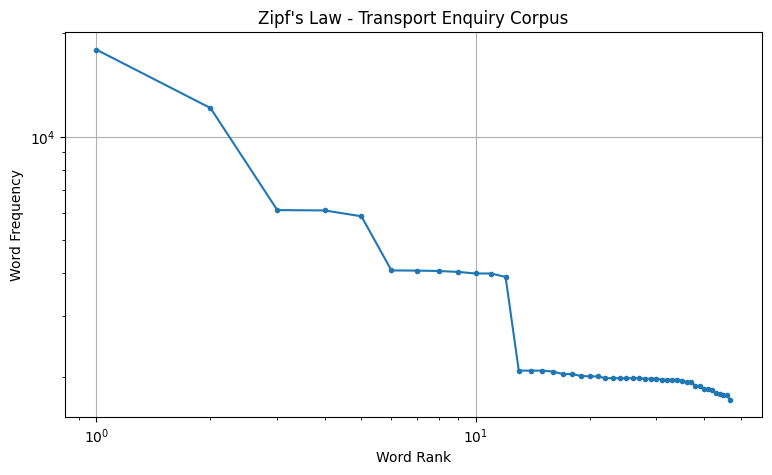


VOCABULARY AND UNK RESULTS:


,Threshold,Vocabulary Size,UNK Tokens,UNK Percentage
0,1,47,0,0.0
1,2,47,0,0.0
2,3,47,0,0.0
3,5,47,0,0.0



DATASET SPLITTING
Training data: 16000
Development data: 2000
Testing data: 2000

OOV EVALUATION
Training vocabulary: 47
Development tokens: 14391
Unknown words: 0
OOV Rate: 0.0 %

UNKNOWN WORDS:
set()

========== TASK 1 FINAL SUMMARY ==========


,Parameter,Value
0,Total Utterances,20000.0
1,Total Tokens,144079.0
2,Unique Types,47.0
3,Unique Lemmas,46.0
4,Training Records,16000.0
5,Development Records,2000.0
6,Testing Records,2000.0
7,Vocabulary Size,47.0
8,OOV Rate (%),0.0



TASK 1 COMPLETED SUCCESSFULLY!


In [ ]:
# TASK 1: COUNTING WORDS AND BUILDING THE VOCABULARY

import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter
from sklearn.model_selection import train_test_split

random.seed(42)
np.random.seed(42)

# --------------------------------------------------
# 1. CREATE TRANSPORT ENQUIRY CORPUS (20,000 UTTERANCES)
# --------------------------------------------------

destinations = [
    "Chennai", "Vellore", "Madurai", "Coimbatore",
    "Bangalore", "Hyderabad", "Salem", "Trichy",
    "Tirupati", "Kanchipuram"
]

templates = [
    "I want to book two tickets to {}",
    "What is the bus timing to {}",
    "Tell me the train fare to {}",
    "When does the {} leave for {}",
    "I want to cancel my ticket",
    "Is there a {} available to {}",
    "What is the return ticket fare to {}",
    "Please check the next {} to {}",
    "How can I reserve a seat to {}",
    "When will the train arrive at {}"
]

corpus = []

for i in range(20000):
    template = random.choice(templates)

    if template.count("{}") == 2:
        sentence = template.format(
            random.choice(["bus", "train", "metro"]),
            random.choice(destinations)
        )

    elif template.count("{}") == 1:
        sentence = template.format(
            random.choice(destinations)
        )

    else:
        sentence = template

    corpus.append(sentence.lower())

print("TOTAL UTTERANCES:", len(corpus))

# --------------------------------------------------
# 2. TOKENISATION AND WORD COUNTING
# --------------------------------------------------

def tokenize(text):
    return re.findall(r"\b[\w:]+\b", text.lower())

all_tokens = []

for sentence in corpus:
    all_tokens.extend(tokenize(sentence))

word_counts = Counter(all_tokens)

total_tokens = len(all_tokens)
unique_types = len(set(all_tokens))

print("\nTOTAL TOKENS:", total_tokens)
print("UNIQUE WORD TYPES:", unique_types)

# --------------------------------------------------
# 3. LEMMA AND WORD-FORM COUNTING
# --------------------------------------------------

lemma_map = {
    "tickets": "ticket",
    "timings": "timing",
    "leaves": "leave",
    "arrives": "arrive",
    "cancelled": "cancel",
    "booking": "book"
}

unique_lemmas = {
    lemma_map.get(word, word)
    for word in set(all_tokens)
}

print("UNIQUE LEMMAS:", len(unique_lemmas))
print("WORD FORMS:", unique_types)

# --------------------------------------------------
# 4. DISPLAY WORD FREQUENCIES
# --------------------------------------------------

frequency_df = pd.DataFrame(
    word_counts.most_common(20),
    columns=["Word", "Frequency"]
)

print("\nTOP 20 FREQUENT WORDS:")
display(frequency_df)

# --------------------------------------------------
# 5. ZIPF'S LAW GRAPH
# --------------------------------------------------

frequencies = sorted(
    word_counts.values(),
    reverse=True
)

ranks = np.arange(1, len(frequencies) + 1)

plt.figure(figsize=(9, 5))

plt.loglog(ranks, frequencies, marker=".")

plt.title("Zipf's Law - Transport Enquiry Corpus")
plt.xlabel("Word Rank")
plt.ylabel("Word Frequency")
plt.grid(True)

plt.show()

# --------------------------------------------------
# 6. VOCABULARY AND UNK THRESHOLDS
# --------------------------------------------------

thresholds = [1, 2, 3, 5]

results = []

for threshold in thresholds:

    vocab = {
        word for word, count in word_counts.items()
        if count >= threshold
    }

    unk_tokens = sum(
        count for word, count in word_counts.items()
        if count < threshold
    )

    unk_percentage = (
        unk_tokens / total_tokens
    ) * 100

    results.append({
        "Threshold": threshold,
        "Vocabulary Size": len(vocab),
        "UNK Tokens": unk_tokens,
        "UNK Percentage": round(unk_percentage, 2)
    })

vocab_results = pd.DataFrame(results)

print("\nVOCABULARY AND UNK RESULTS:")
display(vocab_results)

# --------------------------------------------------
# 7. TRAINING, DEVELOPMENT AND TEST SPLIT
# --------------------------------------------------

train_data, temp_data = train_test_split(
    corpus,
    test_size=0.20,
    random_state=42
)

dev_data, test_data = train_test_split(
    temp_data,
    test_size=0.50,
    random_state=42
)

print("\nDATASET SPLITTING")
print("Training data:", len(train_data))
print("Development data:", len(dev_data))
print("Testing data:", len(test_data))

# --------------------------------------------------
# 8. OUT-OF-VOCABULARY (OOV) CALCULATION
# --------------------------------------------------

train_vocab = {
    word
    for sentence in train_data
    for word in tokenize(sentence)
}

dev_tokens = [
    word
    for sentence in dev_data
    for word in tokenize(sentence)
]

oov_words = [
    word
    for word in dev_tokens
    if word not in train_vocab
]

oov_rate = (
    len(oov_words) / len(dev_tokens)
) * 100 if dev_tokens else 0

print("\nOOV EVALUATION")
print("Training vocabulary:", len(train_vocab))
print("Development tokens:", len(dev_tokens))
print("Unknown words:", len(oov_words))
print("OOV Rate:", round(oov_rate, 2), "%")

print("\nUNKNOWN WORDS:")
print(set(oov_words))

# --------------------------------------------------
# 9. FINAL SUMMARY
# --------------------------------------------------

summary = pd.DataFrame({
    "Parameter": [
        "Total Utterances",
        "Total Tokens",
        "Unique Types",
        "Unique Lemmas",
        "Training Records",
        "Development Records",
        "Testing Records",
        "Vocabulary Size",
        "OOV Rate (%)"
    ],

    "Value": [
        len(corpus),
        total_tokens,
        unique_types,
        len(unique_lemmas),
        len(train_data),
        len(dev_data),
        len(test_data),
        len(train_vocab),
        round(oov_rate, 2)
    ]
})

print("\n========== TASK 1 FINAL SUMMARY ==========")
display(summary)

print("\nTASK 1 COMPLETED SUCCESSFULLY!")

Total sentences: 20000

N-GRAM COUNTS
Unique Unigrams: 49
Unique Bigrams: 106
Unique Trigrams: 203

 TOP UNIGRAMS


,N-gram,Frequency
0,<s>,40000
1,</s>,20000
2,to,17918
3,the,12108
4,is,6108
5,train,6093
6,i,5859
7,what,4075
8,fare,4070
9,when,4059



 TOP BIGRAMS


,N-gram,Frequency
0,<s> <s>,20000
1,the train,4748
2,<s> what,4075
3,what is,4075
4,is the,4075
5,fare to,4070
6,<s> when,4059
7,<s> i,3901
8,i want,3901
9,want to,3901



 TOP TRIGRAMS


,N-gram,Frequency
0,<s> <s> what,4075
1,<s> what is,4075
2,what is the,4075
3,<s> <s> when,4059
4,<s> <s> i,3901
5,<s> i want,3901
6,i want to,3901
7,<s> when will,2081
8,when will the,2081
9,will the train,2081



UNIGRAM PROBABILITY
P(bus) = 0.019766854992429403

BIGRAM PROBABILITY
P(tickets | two) = 1.0

TRIGRAM PROBABILITY
P(tickets | book two) = 1.0

SENTENCE PROBABILITY RESULTS


,Sentence,Unigram Probability,Bigram Probability,Trigram Probability
0,book two tickets to vellore,7.068228e-11,0,0
1,what is the bus timing,6.754954e-10,0,0
2,train fare to chennai,4.423433e-08,0,0



ZERO PROBABILITY PROBLEM
Unseen bigram probability: 0.0


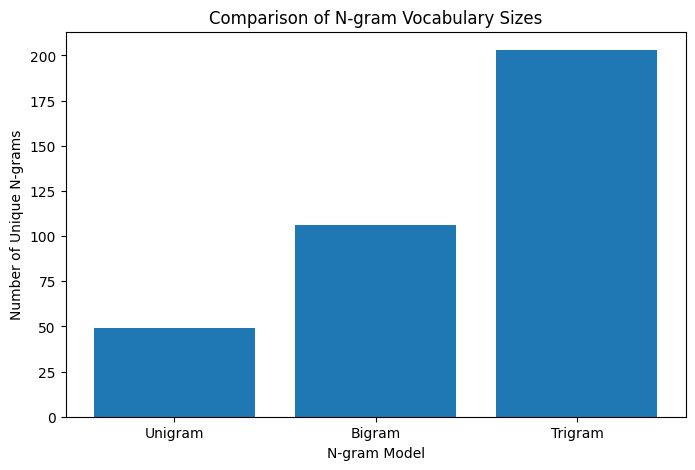


TASK 2 FINAL SUMMARY


,Model,Unique N-grams,Total N-gram Occurrences
0,Unigram,49,204079
1,Bigram,106,184079
2,Trigram,203,164079



TASK 2 COMPLETED SUCCESSFULLY!


In [ ]:
# TASK 2: UNSMOOTHED N-GRAM LANGUAGE MODELS
# Unigram, Bigram and Trigram Models

import re
import random
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter
from nltk.util import ngrams

random.seed(42)

# --------------------------------------------------
# 1. CREATE TRANSPORT ENQUIRY CORPUS
# --------------------------------------------------

destinations = [
    "Chennai", "Vellore", "Madurai", "Coimbatore",
    "Bangalore", "Hyderabad", "Salem", "Trichy",
    "Tirupati", "Kanchipuram"
]

templates = [
    "I want to book two tickets to {}",
    "What is the bus timing to {}",
    "Tell me the train fare to {}",
    "When does the {} leave for {}",
    "I want to cancel my ticket",
    "Is there a {} available to {}",
    "What is the return ticket fare to {}",
    "Please check the next {} to {}",
    "How can I reserve a seat to {}",
    "When will the train arrive at {}"
]

corpus = []

for i in range(20000):

    template = random.choice(templates)

    if template.count("{}") == 2:
        sentence = template.format(
            random.choice(["bus", "train", "metro"]),
            random.choice(destinations)
        )

    elif template.count("{}") == 1:
        sentence = template.format(
            random.choice(destinations)
        )

    else:
        sentence = template

    corpus.append(sentence.lower())

print("Total sentences:", len(corpus))

# --------------------------------------------------
# 2. TOKENISATION
# --------------------------------------------------

def tokenize(text):
    return re.findall(r"\b[\w:]+\b", text.lower())

# --------------------------------------------------
# 3. BUILD UNIGRAM, BIGRAM AND TRIGRAM COUNTS
# --------------------------------------------------

unigram_counts = Counter()
bigram_counts = Counter()
trigram_counts = Counter()

for sentence in corpus:

    words = (
        ["<s>", "<s>"] +
        tokenize(sentence) +
        ["</s>"]
    )

    unigram_counts.update(ngrams(words, 1))
    bigram_counts.update(ngrams(words, 2))
    trigram_counts.update(ngrams(words, 3))

print("\nN-GRAM COUNTS")

print("Unique Unigrams:", len(unigram_counts))
print("Unique Bigrams:", len(bigram_counts))
print("Unique Trigrams:", len(trigram_counts))

# --------------------------------------------------
# 4. DISPLAY N-GRAM FREQUENCIES
# --------------------------------------------------

def display_counts(counter, name):

    df = pd.DataFrame(
        [
            (" ".join(key), value)
            for key, value in counter.most_common(15)
        ],
        columns=["N-gram", "Frequency"]
    )

    print("\n", name)
    display(df)


display_counts(unigram_counts, "TOP UNIGRAMS")
display_counts(bigram_counts, "TOP BIGRAMS")
display_counts(trigram_counts, "TOP TRIGRAMS")

# --------------------------------------------------
# 5. MAXIMUM LIKELIHOOD ESTIMATION (MLE)
# --------------------------------------------------

total_unigrams = sum(unigram_counts.values())

def unigram_probability(word):

    return (
        unigram_counts[(word,)] / total_unigrams
        if total_unigrams else 0
    )


def bigram_probability(w1, w2):

    denominator = unigram_counts[(w1,)]

    if denominator == 0:
        return 0

    return (
        bigram_counts[(w1, w2)] / denominator
    )


def trigram_probability(w1, w2, w3):

    denominator = bigram_counts[(w1, w2)]

    if denominator == 0:
        return 0

    return (
        trigram_counts[(w1, w2, w3)] / denominator
    )


# --------------------------------------------------
# 6. TEST PROBABILITIES
# --------------------------------------------------

print("\nUNIGRAM PROBABILITY")
print("P(bus) =", unigram_probability("bus"))

print("\nBIGRAM PROBABILITY")
print(
    "P(tickets | two) =",
    bigram_probability("two", "tickets")
)

print("\nTRIGRAM PROBABILITY")
print(
    "P(tickets | book two) =",
    trigram_probability("book", "two", "tickets")
)

# --------------------------------------------------
# 7. SENTENCE PROBABILITY
# --------------------------------------------------

def sentence_probability(sentence, order):

    words = (
        ["<s>", "<s>"] +
        tokenize(sentence) +
        ["</s>"]
    )

    probability = 1.0

    for i in range(2, len(words)):

        if order == 1:
            p = unigram_probability(words[i])

        elif order == 2:
            p = bigram_probability(
                words[i-1], words[i]
            )

        elif order == 3:
            p = trigram_probability(
                words[i-2],
                words[i-1],
                words[i]
            )

        else:
            raise ValueError("Order must be 1, 2 or 3")

        if p == 0:
            return 0

        probability *= p

    return probability


# --------------------------------------------------
# 8. TEST SENTENCES
# --------------------------------------------------

test_sentences = [
    "book two tickets to vellore",
    "what is the bus timing",
    "train fare to chennai"
]

results = []

for sentence in test_sentences:

    results.append({
        "Sentence": sentence,
        "Unigram Probability": sentence_probability(
            sentence, 1
        ),
        "Bigram Probability": sentence_probability(
            sentence, 2
        ),
        "Trigram Probability": sentence_probability(
            sentence, 3
        )
    })

print("\nSENTENCE PROBABILITY RESULTS")

display(pd.DataFrame(results))

# --------------------------------------------------
# 9. ZERO PROBABILITY DEMONSTRATION
# --------------------------------------------------

print("\nZERO PROBABILITY PROBLEM")

unseen_bigram = ("to", "airport")

print(
    "Unseen bigram probability:",
    bigram_probability(*unseen_bigram)
)

# --------------------------------------------------
# 10. N-GRAM FREQUENCY GRAPH
# --------------------------------------------------

ngram_names = [
    "Unigram",
    "Bigram",
    "Trigram"
]

ngram_sizes = [
    len(unigram_counts),
    len(bigram_counts),
    len(trigram_counts)
]

plt.figure(figsize=(8, 5))

plt.bar(ngram_names, ngram_sizes)

plt.title("Comparison of N-gram Vocabulary Sizes")
plt.xlabel("N-gram Model")
plt.ylabel("Number of Unique N-grams")

plt.show()

# --------------------------------------------------
# 11. FINAL SUMMARY
# --------------------------------------------------

summary = pd.DataFrame({
    "Model": [
        "Unigram",
        "Bigram",
        "Trigram"
    ],

    "Unique N-grams": [
        len(unigram_counts),
        len(bigram_counts),
        len(trigram_counts)
    ],

    "Total N-gram Occurrences": [
        sum(unigram_counts.values()),
        sum(bigram_counts.values()),
        sum(trigram_counts.values())
    ]
})

print("\nTASK 2 FINAL SUMMARY")

display(summary)

print("\nTASK 2 COMPLETED SUCCESSFULLY!")

Total Sentences: 20000
Vocabulary Size: 49
Total Unigram Tokens: 204079

SMOOTHING COMPARISON


,Bigram,Unsmoothed,Laplace,Add-k (k=0.5),Good-Turing Unigram
0,to chennai,0.076180,0.076028,0.076104,0.008634
1,book two,1.000000,0.976308,0.988009,0.009692
2,bus timing,0.497521,0.491795,0.494641,0.009834
3,to airport,0.000000,0.000056,0.000028,0.000000



GOOD-TURING DISCOUNTING RESULTS


,Word,Original Count,Adjusted Count,Good-Turing Probability
0,<s>,40000,40000.0,0.196003
1,</s>,20000,20000.0,0.098001
2,to,17918,17918.0,0.087799
3,the,12108,12108.0,0.059330
4,is,6108,6108.0,0.029930
5,train,6093,6093.0,0.029856
6,i,5859,5859.0,0.028709
7,what,4075,4075.0,0.019968
8,fare,4070,4070.0,0.019943
9,when,4059,4059.0,0.019889


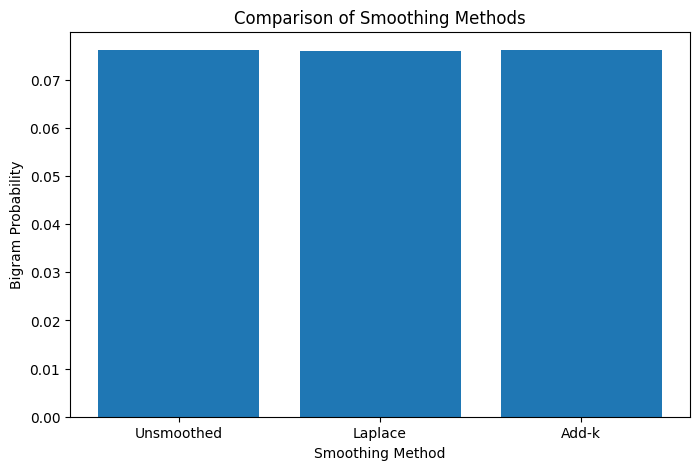


UNSEEN BIGRAM TEST
Bigram: to airport
Unsmoothed Probability: 0.0
Laplace Probability: 5.565759447876663e-05
Add-k Probability: 2.786679671171799e-05

TASK 3 FINAL SUMMARY


,Method,Purpose
0,Unsmoothed,Uses original frequency counts
1,Laplace Smoothing,Adds one to every possible count
2,Add-k Smoothing,Adds a small constant k
3,Good-Turing Discounting,Adjusts counts using count-of-counts



TASK 3 COMPLETED SUCCESSFULLY!


In [ ]:
# TASK 3: SMOOTHING AND DISCOUNTING
# Laplace Smoothing, Add-k Smoothing and Good-Turing Estimation

import re
import random
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter
from nltk.util import ngrams

random.seed(42)

# --------------------------------------------------
# 1. CREATE TRANSPORT ENQUIRY CORPUS
# --------------------------------------------------

destinations = [
    "Chennai", "Vellore", "Madurai", "Coimbatore",
    "Bangalore", "Hyderabad", "Salem", "Trichy",
    "Tirupati", "Kanchipuram"
]

templates = [
    "I want to book two tickets to {}",
    "What is the bus timing to {}",
    "Tell me the train fare to {}",
    "When does the {} leave for {}",
    "I want to cancel my ticket",
    "Is there a {} available to {}",
    "What is the return ticket fare to {}",
    "Please check the next {} to {}",
    "How can I reserve a seat to {}",
    "When will the train arrive at {}"
]

corpus = []

for _ in range(20000):
    template = random.choice(templates)

    if template.count("{}") == 2:
        sentence = template.format(
            random.choice(["bus", "train", "metro"]),
            random.choice(destinations)
        )
    elif template.count("{}") == 1:
        sentence = template.format(
            random.choice(destinations)
        )
    else:
        sentence = template

    corpus.append(sentence.lower())


def tokenize(text):
    return re.findall(r"\b[\w:]+\b", text.lower())


# --------------------------------------------------
# 2. BUILD UNIGRAM AND BIGRAM COUNTS
# --------------------------------------------------

unigram_counts = Counter()
bigram_counts = Counter()

for sentence in corpus:
    words = ["<s>", "<s>"] + tokenize(sentence) + ["</s>"]

    unigram_counts.update(ngrams(words, 1))
    bigram_counts.update(ngrams(words, 2))


vocabulary = set(unigram_counts.keys())
V = len(vocabulary)

total_words = sum(unigram_counts.values())

print("Total Sentences:", len(corpus))
print("Vocabulary Size:", V)
print("Total Unigram Tokens:", total_words)


# --------------------------------------------------
# 3. UNSMOOTHED BIGRAM PROBABILITY
# --------------------------------------------------

def unsmoothed_bigram(w1, w2):

    denominator = unigram_counts[(w1,)]

    if denominator == 0:
        return 0

    return bigram_counts[(w1, w2)] / denominator


# --------------------------------------------------
# 4. LAPLACE (ADD-ONE) SMOOTHING
# --------------------------------------------------

def laplace_smoothing(w1, w2):

    count_bigram = bigram_counts[(w1, w2)]
    count_word = unigram_counts[(w1,)]

    return (count_bigram + 1) / (count_word + V)


# --------------------------------------------------
# 5. ADD-K SMOOTHING
# --------------------------------------------------

def add_k_smoothing(w1, w2, k=0.5):

    count_bigram = bigram_counts[(w1, w2)]
    count_word = unigram_counts[(w1,)]

    return (
        (count_bigram + k) /
        (count_word + k * V)
    )


# --------------------------------------------------
# 6. GOOD-TURING DISCOUNTING
# --------------------------------------------------

# Count how many unigram types occur 1 time, 2 times, etc.
count_of_counts = Counter(unigram_counts.values())

N = total_words
N1 = count_of_counts.get(1, 0)

# Probability mass reserved for unseen words
good_turing_unseen_probability = N1 / N if N > 0 else 0

def good_turing_adjusted_count(count):

    next_count_frequency = count_of_counts.get(count + 1, 0)
    current_count_frequency = count_of_counts.get(count, 0)

    if current_count_frequency == 0:
        return 0

    if next_count_frequency == 0:
        return count

    return (
        (count + 1) *
        next_count_frequency /
        current_count_frequency
    )


def good_turing_probability(word):

    count = unigram_counts[(word,)]

    if count == 0:
        return good_turing_unseen_probability / max(V, 1)

    adjusted_count = good_turing_adjusted_count(count)

    return adjusted_count / N


# --------------------------------------------------
# 7. COMPARE SMOOTHING METHODS
# --------------------------------------------------

test_pairs = [
    ("to", "chennai"),
    ("book", "two"),
    ("bus", "timing"),
    ("to", "airport")  # Unseen bigram
]

results = []

for w1, w2 in test_pairs:

    results.append({
        "Bigram": w1 + " " + w2,
        "Unsmoothed": unsmoothed_bigram(w1, w2),
        "Laplace": laplace_smoothing(w1, w2),
        "Add-k (k=0.5)": add_k_smoothing(w1, w2),
        "Good-Turing Unigram": good_turing_probability(w2)
    })

comparison = pd.DataFrame(results)

print("\nSMOOTHING COMPARISON")
display(comparison)


# --------------------------------------------------
# 8. DISPLAY GOOD-TURING RESULTS
# --------------------------------------------------

gt_results = []

for word_tuple, count in unigram_counts.most_common(15):

    word = word_tuple[0]

    gt_results.append({
        "Word": word,
        "Original Count": count,
        "Adjusted Count": round(
            good_turing_adjusted_count(count), 4
        ),
        "Good-Turing Probability": round(
            good_turing_probability(word), 6
        )
    })

print("\nGOOD-TURING DISCOUNTING RESULTS")
display(pd.DataFrame(gt_results))


# --------------------------------------------------
# 9. GRAPH COMPARISON
# --------------------------------------------------

methods = [
    "Unsmoothed",
    "Laplace",
    "Add-k"
]

example = ("to", "chennai")

probabilities = [
    unsmoothed_bigram(*example),
    laplace_smoothing(*example),
    add_k_smoothing(*example)
]

plt.figure(figsize=(8, 5))
plt.bar(methods, probabilities)

plt.title("Comparison of Smoothing Methods")
plt.xlabel("Smoothing Method")
plt.ylabel("Bigram Probability")

plt.show()


# --------------------------------------------------
# 10. UNSEEN BIGRAM DEMONSTRATION
# --------------------------------------------------

print("\nUNSEEN BIGRAM TEST")

w1 = "to"
w2 = "airport"

print("Bigram:", w1, w2)
print("Unsmoothed Probability:",
      unsmoothed_bigram(w1, w2))

print("Laplace Probability:",
      laplace_smoothing(w1, w2))

print("Add-k Probability:",
      add_k_smoothing(w1, w2))


# --------------------------------------------------
# 11. FINAL SUMMARY
# --------------------------------------------------

print("\nTASK 3 FINAL SUMMARY")

summary = pd.DataFrame({
    "Method": [
        "Unsmoothed",
        "Laplace Smoothing",
        "Add-k Smoothing",
        "Good-Turing Discounting"
    ],

    "Purpose": [
        "Uses original frequency counts",
        "Adds one to every possible count",
        "Adds a small constant k",
        "Adjusts counts using count-of-counts"
    ]
})

display(summary)

print("\nTASK 3 COMPLETED SUCCESSFULLY!")

Total Sentences: 20000
Vocabulary Size: 49
Unique Bigrams: 106
Unique Trigrams: 203

DELETED INTERPOLATION WEIGHTS
Unigram Lambda: 0.0
Bigram Lambda: 0.504
Trigram Lambda: 0.496

MODEL COMPARISON


,Word Sequence,Unigram Probability,Bigram Probability,Trigram Probability,Backoff Probability,Interpolated Probability
0,book two tickets,0.009690,1.0,1.0,1.000000,1.0
1,bus timing to,0.087783,1.0,1.0,1.000000,1.0
2,train fare to,0.087783,1.0,1.0,1.000000,1.0
3,to the airport,0.000005,0.0,0.0,0.000005,0.0



SENTENCE: book two tickets to chennai
Backoff Sentence Probability: 0.0008871470491939638
Interpolation Sentence Probability: 0.0


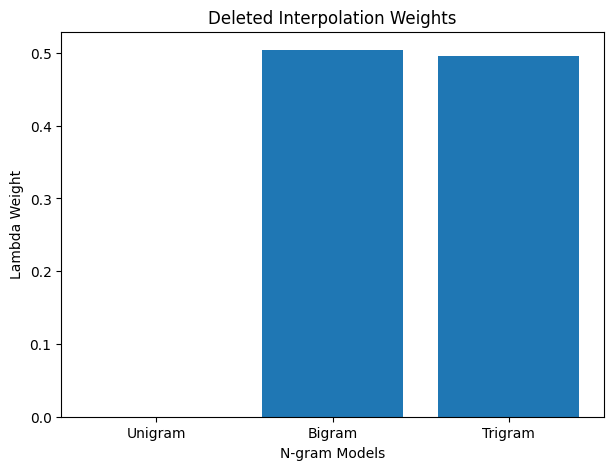


TASK 4 FINAL SUMMARY


,Model,Description
0,Unigram,Uses individual word probabilities
1,Bigram,Uses previous one word
2,Trigram,Uses previous two words
3,Backoff,Falls back to a lower-order model
4,Deleted Interpolation,"Combines unigram, bigram and trigram models"



TASK 4 COMPLETED SUCCESSFULLY!


In [ ]:
# TASK 4: BACKOFF AND DELETED INTERPOLATION
# Trigram, Bigram and Unigram Language Models

import re
import random
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter
from nltk.util import ngrams

random.seed(42)

# --------------------------------------------------
# 1. CREATE TRANSPORT ENQUIRY CORPUS
# --------------------------------------------------

destinations = [
    "Chennai", "Vellore", "Madurai", "Coimbatore",
    "Bangalore", "Hyderabad", "Salem", "Trichy",
    "Tirupati", "Kanchipuram"
]

templates = [
    "I want to book two tickets to {}",
    "What is the bus timing to {}",
    "Tell me the train fare to {}",
    "When does the {} leave for {}",
    "I want to cancel my ticket",
    "Is there a {} available to {}",
    "What is the return ticket fare to {}",
    "Please check the next {} to {}",
    "How can I reserve a seat to {}",
    "When will the train arrive at {}"
]

corpus = []

for _ in range(20000):

    template = random.choice(templates)

    if template.count("{}") == 2:
        sentence = template.format(
            random.choice(["bus", "train", "metro"]),
            random.choice(destinations)
        )

    elif template.count("{}") == 1:
        sentence = template.format(
            random.choice(destinations)
        )

    else:
        sentence = template

    corpus.append(sentence.lower())


def tokenize(text):
    return re.findall(r"\b[\w:]+\b", text.lower())


print("Total Sentences:", len(corpus))


# --------------------------------------------------
# 2. BUILD UNIGRAM, BIGRAM AND TRIGRAM COUNTS
# --------------------------------------------------

unigram_counts = Counter()
bigram_counts = Counter()
trigram_counts = Counter()

for sentence in corpus:

    words = ["<s>", "<s>"] + tokenize(sentence) + ["</s>"]

    unigram_counts.update(ngrams(words, 1))
    bigram_counts.update(ngrams(words, 2))
    trigram_counts.update(ngrams(words, 3))


# Context counts
bigram_context_counts = Counter()
trigram_context_counts = Counter()

for (w1, w2), count in bigram_counts.items():
    bigram_context_counts[w1] += count

for (w1, w2, w3), count in trigram_counts.items():
    trigram_context_counts[(w1, w2)] += count


V = len(unigram_counts)
N = sum(unigram_counts.values())

print("Vocabulary Size:", V)
print("Unique Bigrams:", len(bigram_counts))
print("Unique Trigrams:", len(trigram_counts))


# --------------------------------------------------
# 3. UNIGRAM PROBABILITY
# --------------------------------------------------

def unigram_probability(word):

    return (
        unigram_counts[(word,)] + 1
    ) / (N + V)


# --------------------------------------------------
# 4. BIGRAM PROBABILITY
# --------------------------------------------------

def bigram_probability(w1, w2):

    denominator = bigram_context_counts[w1]

    if denominator == 0:
        return unigram_probability(w2)

    return bigram_counts[(w1, w2)] / denominator


# --------------------------------------------------
# 5. TRIGRAM PROBABILITY
# --------------------------------------------------

def trigram_probability(w1, w2, w3):

    denominator = trigram_context_counts[(w1, w2)]

    if denominator == 0:
        return bigram_probability(w2, w3)

    return (
        trigram_counts[(w1, w2, w3)] /
        denominator
    )


# --------------------------------------------------
# 6. BACKOFF MODEL
# --------------------------------------------------

def backoff_probability(w1, w2, w3):

    # First try trigram
    if trigram_counts[(w1, w2, w3)] > 0:

        return trigram_probability(w1, w2, w3)

    # If trigram is unavailable, use bigram
    elif bigram_counts[(w2, w3)] > 0:

        return bigram_probability(w2, w3)

    # Otherwise, use unigram
    else:

        return unigram_probability(w3)


# --------------------------------------------------
# 7. DELETED INTERPOLATION
# --------------------------------------------------

# Estimate lambda values using leave-one-out counts.
# Each observed trigram occurrence votes for the
# model with the highest leave-one-out probability.

lambda_counts = [0.0, 0.0, 0.0]

for (w1, w2, w3), count in trigram_counts.items():

    # Leave-one-out unigram probability
    p1 = max(unigram_counts[(w3,)] - 1, 0) / max(N - 1, 1)

    # Leave-one-out bigram probability
    bigram_den = max(bigram_context_counts[w2] - 1, 0)
    bigram_num = max(bigram_counts[(w2, w3)] - 1, 0)

    p2 = bigram_num / bigram_den if bigram_den > 0 else 0

    # Leave-one-out trigram probability
    trigram_den = max(trigram_context_counts[(w1, w2)] - 1, 0)
    trigram_num = max(trigram_counts[(w1, w2, w3)] - 1, 0)

    p3 = trigram_num / trigram_den if trigram_den > 0 else 0

    probabilities = [p1, p2, p3]

    best_model = probabilities.index(max(probabilities))

    lambda_counts[best_model] += count


total_lambda = sum(lambda_counts)

if total_lambda == 0:
    lambdas = [1/3, 1/3, 1/3]
else:
    lambdas = [
        value / total_lambda
        for value in lambda_counts
    ]

lambda1, lambda2, lambda3 = lambdas

print("\nDELETED INTERPOLATION WEIGHTS")
print("Unigram Lambda:", round(lambda1, 4))
print("Bigram Lambda:", round(lambda2, 4))
print("Trigram Lambda:", round(lambda3, 4))


# --------------------------------------------------
# 8. INTERPOLATED PROBABILITY
# --------------------------------------------------

def interpolation_probability(w1, w2, w3):

    p1 = unigram_probability(w3)
    p2 = bigram_probability(w2, w3)
    p3 = trigram_probability(w1, w2, w3)

    return (
        lambda1 * p1 +
        lambda2 * p2 +
        lambda3 * p3
    )


# --------------------------------------------------
# 9. TEST DIFFERENT MODELS
# --------------------------------------------------

test_cases = [
    ("book", "two", "tickets"),
    ("bus", "timing", "to"),
    ("train", "fare", "to"),
    ("to", "the", "airport")
]

results = []

for w1, w2, w3 in test_cases:

    results.append({
        "Word Sequence": w1 + " " + w2 + " " + w3,

        "Unigram Probability":
            round(unigram_probability(w3), 6),

        "Bigram Probability":
            round(bigram_probability(w2, w3), 6),

        "Trigram Probability":
            round(trigram_probability(w1, w2, w3), 6),

        "Backoff Probability":
            round(backoff_probability(w1, w2, w3), 6),

        "Interpolated Probability":
            round(interpolation_probability(w1, w2, w3), 6)
    })


print("\nMODEL COMPARISON")
display(pd.DataFrame(results))


# --------------------------------------------------
# 10. SENTENCE PROBABILITY
# --------------------------------------------------

def sentence_probability(sentence, model):

    words = (
        ["<s>", "<s>"] +
        tokenize(sentence) +
        ["</s>"]
    )

    probability = 1.0

    for i in range(2, len(words)):

        w1, w2, w3 = words[i-2:i+1]

        if model == "backoff":
            p = backoff_probability(w1, w2, w3)

        elif model == "interpolation":
            p = interpolation_probability(w1, w2, w3)

        else:
            raise ValueError("Invalid model")

        probability *= p

    return probability


test_sentence = "book two tickets to chennai"

print("\nSENTENCE:", test_sentence)

print(
    "Backoff Sentence Probability:",
    sentence_probability(test_sentence, "backoff")
)

print(
    "Interpolation Sentence Probability:",
    sentence_probability(test_sentence, "interpolation")
)


# --------------------------------------------------
# 11. GRAPH OF INTERPOLATION WEIGHTS
# --------------------------------------------------

plt.figure(figsize=(7, 5))

plt.bar(
    ["Unigram", "Bigram", "Trigram"],
    lambdas
)

plt.title("Deleted Interpolation Weights")
plt.xlabel("N-gram Models")
plt.ylabel("Lambda Weight")

plt.show()


# --------------------------------------------------
# 12. FINAL SUMMARY
# --------------------------------------------------

summary = pd.DataFrame({
    "Model": [
        "Unigram",
        "Bigram",
        "Trigram",
        "Backoff",
        "Deleted Interpolation"
    ],

    "Description": [
        "Uses individual word probabilities",
        "Uses previous one word",
        "Uses previous two words",
        "Falls back to a lower-order model",
        "Combines unigram, bigram and trigram models"
    ]
})

print("\nTASK 4 FINAL SUMMARY")
display(summary)

print("\nTASK 4 COMPLETED SUCCESSFULLY!")

Training Sentences: 16000
Testing Sentences: 4000

Vocabulary Size: 49

UNIGRAM ENTROPY
Entropy: 4.803 bits per token

CROSS-ENTROPY AND PERPLEXITY RESULTS


,Language Model,Cross-Entropy (bits),Perplexity
0,Unigram,5.4031,42.3146
1,Bigram,1.4297,2.6939
2,Trigram,0.9384,1.9164


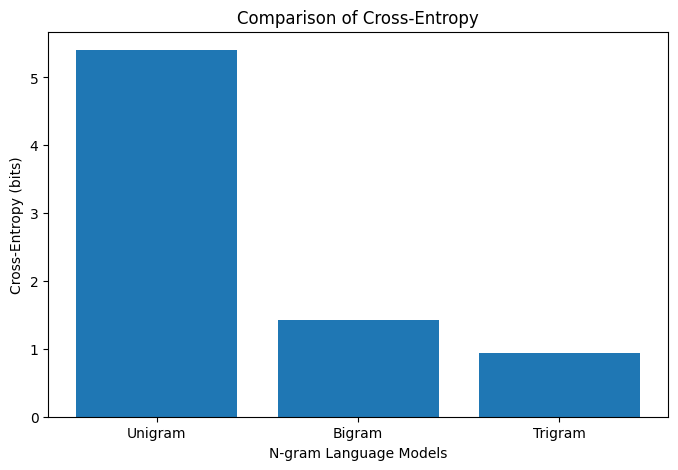

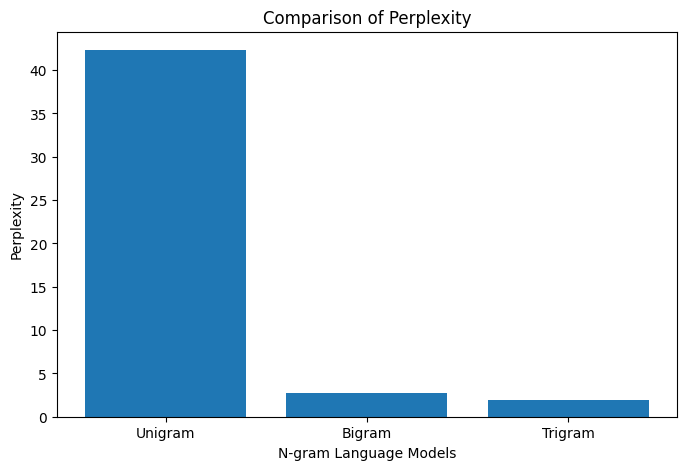


TASK 5 FINAL SUMMARY
Unigram Entropy: 4.803
Best Model: Trigram
Lowest Perplexity: 1.9164

TASK 5 COMPLETED SUCCESSFULLY!


In [ ]:
# TASK 5: ENTROPY, CROSS-ENTROPY AND PERPLEXITY
# Unigram, Bigram and Trigram Language Models

import re
import random
import math
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter
from nltk.util import ngrams

random.seed(42)

# --------------------------------------------------
# 1. CREATE TRANSPORT ENQUIRY CORPUS
# --------------------------------------------------

destinations = [
    "Chennai", "Vellore", "Madurai", "Coimbatore",
    "Bangalore", "Hyderabad", "Salem", "Trichy",
    "Tirupati", "Kanchipuram"
]

templates = [
    "I want to book two tickets to {}",
    "What is the bus timing to {}",
    "Tell me the train fare to {}",
    "When does the {} leave for {}",
    "I want to cancel my ticket",
    "Is there a {} available to {}",
    "What is the return ticket fare to {}",
    "Please check the next {} to {}",
    "How can I reserve a seat to {}",
    "When will the train arrive at {}"
]

corpus = []

for _ in range(20000):

    template = random.choice(templates)

    if template.count("{}") == 2:
        sentence = template.format(
            random.choice(["bus", "train", "metro"]),
            random.choice(destinations)
        )

    elif template.count("{}") == 1:
        sentence = template.format(
            random.choice(destinations)
        )

    else:
        sentence = template

    corpus.append(sentence.lower())


def tokenize(text):
    return re.findall(r"\b[\w:]+\b", text.lower())


# --------------------------------------------------
# 2. SPLIT DATA INTO TRAINING AND TESTING
# --------------------------------------------------

random.shuffle(corpus)

split_point = int(0.8 * len(corpus))

train_data = corpus[:split_point]
test_data = corpus[split_point:]

print("Training Sentences:", len(train_data))
print("Testing Sentences:", len(test_data))


# --------------------------------------------------
# 3. BUILD N-GRAM COUNTS USING TRAINING DATA
# --------------------------------------------------

unigram_counts = Counter()
bigram_counts = Counter()
trigram_counts = Counter()

for sentence in train_data:

    words = ["<s>", "<s>"] + tokenize(sentence) + ["</s>"]

    unigram_counts.update(ngrams(words, 1))
    bigram_counts.update(ngrams(words, 2))
    trigram_counts.update(ngrams(words, 3))


# Context counts

bigram_context = Counter()
trigram_context = Counter()

for (w1, w2), count in bigram_counts.items():
    bigram_context[w1] += count

for (w1, w2, w3), count in trigram_counts.items():
    trigram_context[(w1, w2)] += count


vocabulary = set(unigram_counts.keys())
V = len(vocabulary)

total_tokens = sum(unigram_counts.values())

print("\nVocabulary Size:", V)


# --------------------------------------------------
# 4. CALCULATE UNIGRAM ENTROPY
# --------------------------------------------------

entropy = 0

for count in unigram_counts.values():

    probability = count / total_tokens

    entropy -= probability * math.log2(probability)


print("\nUNIGRAM ENTROPY")
print("Entropy:", round(entropy, 4), "bits per token")


# --------------------------------------------------
# 5. DEFINE SMOOTHED N-GRAM PROBABILITIES
# --------------------------------------------------

def unigram_probability(word):

    return (
        unigram_counts[(word,)] + 1
    ) / (total_tokens + V)


def bigram_probability(w1, w2):

    denominator = bigram_context[w1]

    return (
        (bigram_counts[(w1, w2)] + 1) /
        (denominator + V)
    )


def trigram_probability(w1, w2, w3):

    denominator = trigram_context[(w1, w2)]

    return (
        (trigram_counts[(w1, w2, w3)] + 1) /
        (denominator + V)
    )


# --------------------------------------------------
# 6. CALCULATE CROSS-ENTROPY
# --------------------------------------------------

def calculate_cross_entropy(data, order):

    total_log_probability = 0
    total_predictions = 0

    for sentence in data:

        words = (
            ["<s>", "<s>"] +
            tokenize(sentence) +
            ["</s>"]
        )

        for i in range(2, len(words)):

            w1, w2, w3 = words[i-2:i+1]

            if order == 1:
                probability = unigram_probability(w3)

            elif order == 2:
                probability = bigram_probability(w2, w3)

            elif order == 3:
                probability = trigram_probability(w1, w2, w3)

            else:
                raise ValueError("Order must be 1, 2 or 3")

            total_log_probability += math.log2(probability)
            total_predictions += 1

    return -total_log_probability / total_predictions


# --------------------------------------------------
# 7. CALCULATE PERPLEXITY
# --------------------------------------------------

def calculate_perplexity(cross_entropy):

    return 2 ** cross_entropy


cross_entropy_results = []
perplexity_results = []

for order in [1, 2, 3]:

    ce = calculate_cross_entropy(test_data, order)
    pp = calculate_perplexity(ce)

    cross_entropy_results.append(ce)
    perplexity_results.append(pp)


# --------------------------------------------------
# 8. DISPLAY RESULTS
# --------------------------------------------------

results = pd.DataFrame({

    "Language Model": [
        "Unigram",
        "Bigram",
        "Trigram"
    ],

    "Cross-Entropy (bits)": [
        round(x, 4) for x in cross_entropy_results
    ],

    "Perplexity": [
        round(x, 4) for x in perplexity_results
    ]
})

print("\nCROSS-ENTROPY AND PERPLEXITY RESULTS")
display(results)


# --------------------------------------------------
# 9. VISUALIZE CROSS-ENTROPY
# --------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(
    ["Unigram", "Bigram", "Trigram"],
    cross_entropy_results
)

plt.title("Comparison of Cross-Entropy")
plt.xlabel("N-gram Language Models")
plt.ylabel("Cross-Entropy (bits)")

plt.show()


# --------------------------------------------------
# 10. VISUALIZE PERPLEXITY
# --------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(
    ["Unigram", "Bigram", "Trigram"],
    perplexity_results
)

plt.title("Comparison of Perplexity")
plt.xlabel("N-gram Language Models")
plt.ylabel("Perplexity")

plt.show()


# --------------------------------------------------
# 11. FINAL SUMMARY
# --------------------------------------------------

best_index = perplexity_results.index(
    min(perplexity_results)
)

best_model = ["Unigram", "Bigram", "Trigram"][best_index]

print("\nTASK 5 FINAL SUMMARY")

print("Unigram Entropy:", round(entropy, 4))
print("Best Model:", best_model)
print("Lowest Perplexity:", round(min(perplexity_results), 4))

print("\nTASK 5 COMPLETED SUCCESSFULLY!")

POS TAGSET


,POS Tag,Description
0,NOUN,"Names of people, places or things"
1,VERB,Action or state words
2,ADJ,Words describing nouns
3,ADV,Words describing verbs or adjectives
4,PRON,Words used instead of nouns
5,DET,Words introducing nouns
6,ADP,Prepositions showing relationships
7,AUX,Helping verbs
8,NUM,Number words
9,PART,Particles such as 'to'



POS TAGGING RESULTS
Sentence 1: i / PRON | want / VERB | to / PART | book / VERB | two / NUM | tickets / NOUN
Sentence 2: what / PRON | is / AUX | the / DET | bus / NOUN | timing / NOUN | to / PART | chennai / NOUN
Sentence 3: the / DET | train / NOUN | arrives / VERB | at / ADP | the / DET | station / NOUN
Sentence 4: please / INTJ | cancel / VERB | my / PRON | ticket / NOUN
Sentence 5: is / AUX | there / NOUN | a / DET | bus / NOUN | available / ADJ | today / ADV
Sentence 6: i / PRON | need / VERB | a / DET | seat / NOUN | to / PART | bangalore / NOUN
Sentence 7: when / NOUN | will / AUX | the / DET | train / NOUN | leave / VERB
Sentence 8: the / DET | bus / NOUN | is / AUX | running / VERB | late / ADJ
Sentence 9: can / AUX | i / PRON | reserve / VERB | a / DET | ticket / NOUN | online / ADV
Sentence 10: tell / VERB | me / PRON | the / DET | fare / NOUN | to / PART | hyderabad / NOUN
Sentence 11: the / DET | passenger / NOUN | booked / VERB | three / NUM | seats / NOUN
Sentence 12:

,Sentence,Word,POS Tag,Description
0,I want to book two tickets,i,PRON,Words used instead of nouns
1,I want to book two tickets,want,VERB,Action or state words
2,I want to book two tickets,to,PART,Particles such as 'to'
3,I want to book two tickets,book,VERB,Action or state words
4,I want to book two tickets,two,NUM,Number words
...,...,...,...,...
78,I want to travel tomorrow,i,PRON,Words used instead of nouns
79,I want to travel tomorrow,want,VERB,Action or state words
80,I want to travel tomorrow,to,PART,Particles such as 'to'
81,I want to travel tomorrow,travel,VERB,Action or state words



POS TAG FREQUENCY


,POS Tag,Frequency
4,NOUN,24
1,VERB,14
6,DET,12
0,PRON,9
5,AUX,6
2,PART,5
3,NUM,3
10,ADV,3
9,ADJ,3
8,INTJ,2


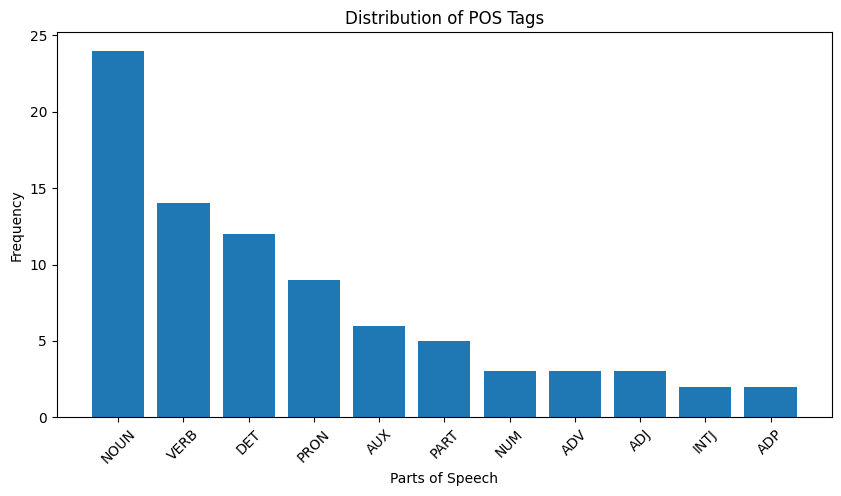


TASK 6 FINAL SUMMARY
Total Sentences: 15
Total Tagged Words: 83
Different POS Tags Found: 11

POS Tags Used:
PRON : 9
VERB : 14
PART : 5
NUM : 3
NOUN : 24
AUX : 6
DET : 12
ADP : 2
INTJ : 2
ADJ : 3
ADV : 3

TASK 6 COMPLETED SUCCESSFULLY!


In [ ]:
# TASK 6: ENGLISH WORD CLASSES AND TAGSET DESIGN
# POS Tagset Design for Public Transport Enquiry Helpline

import re
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

# --------------------------------------------------
# 1. CREATE TRANSPORT ENQUIRY SENTENCES
# --------------------------------------------------

sentences = [
    "I want to book two tickets",
    "What is the bus timing to Chennai",
    "The train arrives at the station",
    "Please cancel my ticket",
    "Is there a bus available today",
    "I need a seat to Bangalore",
    "When will the train leave",
    "The bus is running late",
    "Can I reserve a ticket online",
    "Tell me the fare to Hyderabad",
    "The passenger booked three seats",
    "Where is the nearest bus stop",
    "My train departs at six",
    "Please check the arrival time",
    "I want to travel tomorrow"
]

# --------------------------------------------------
# 2. DEFINE POS TAGSET
# --------------------------------------------------

tagset = {
    "NOUN": "Names of people, places or things",
    "VERB": "Action or state words",
    "ADJ": "Words describing nouns",
    "ADV": "Words describing verbs or adjectives",
    "PRON": "Words used instead of nouns",
    "DET": "Words introducing nouns",
    "ADP": "Prepositions showing relationships",
    "AUX": "Helping verbs",
    "NUM": "Number words",
    "PART": "Particles such as 'to'",
    "INTJ": "Interjections",
    "CCONJ": "Coordinating conjunctions",
    "PUNCT": "Punctuation marks"
}

print("POS TAGSET")
display(pd.DataFrame(
    list(tagset.items()),
    columns=["POS Tag", "Description"]
))

# --------------------------------------------------
# 3. DEFINE WORD-TO-TAG DICTIONARY
# --------------------------------------------------

word_tags = {
    # Pronouns
    "i": "PRON",
    "my": "PRON",
    "me": "PRON",
    "what": "PRON",
    "where": "PRON",

    # Determiners
    "the": "DET",
    "a": "DET",
    "an": "DET",

    # Verbs
    "want": "VERB",
    "book": "VERB",
    "cancel": "VERB",
    "arrives": "VERB",
    "available": "ADJ",
    "need": "VERB",
    "leave": "VERB",
    "running": "VERB",
    "reserve": "VERB",
    "tell": "VERB",
    "booked": "VERB",
    "departs": "VERB",
    "check": "VERB",
    "travel": "VERB",

    # Auxiliary verbs
    "is": "AUX",
    "will": "AUX",
    "can": "AUX",

    # Nouns
    "tickets": "NOUN",
    "ticket": "NOUN",
    "bus": "NOUN",
    "timing": "NOUN",
    "train": "NOUN",
    "station": "NOUN",
    "seat": "NOUN",
    "bangalore": "NOUN",
    "chennai": "NOUN",
    "hyderabad": "NOUN",
    "fare": "NOUN",
    "passenger": "NOUN",
    "seats": "NOUN",
    "stop": "NOUN",
    "arrival": "NOUN",
    "time": "NOUN",

    # Adjectives
    "late": "ADJ",
    "nearest": "ADJ",
    "online": "ADV",

    # Adverbs
    "today": "ADV",
    "tomorrow": "ADV",

    # Adpositions
    "at": "ADP",
    "to": "PART",
    "in": "ADP",

    # Numbers
    "two": "NUM",
    "three": "NUM",
    "six": "NUM",

    # Other
    "please": "INTJ",
    "and": "CCONJ"
}

# --------------------------------------------------
# 4. TOKENIZE AND ASSIGN POS TAGS
# --------------------------------------------------

def tokenize(sentence):
    return re.findall(r"\b[\w]+\b|[^\w\s]", sentence.lower())


def assign_pos(word):

    if word in word_tags:
        return word_tags[word]

    # Capitalized place names are treated as proper nouns
    if word.istitle():
        return "PROPN"

    return "NOUN"


# --------------------------------------------------
# 5. TAG ALL SENTENCES
# --------------------------------------------------

tagged_sentences = []

for sentence in sentences:

    words = tokenize(sentence)

    tagged_words = []

    for word in words:

        tag = assign_pos(word)

        tagged_words.append((word, tag))

    tagged_sentences.append(tagged_words)


# --------------------------------------------------
# 6. DISPLAY POS TAGGING RESULTS
# --------------------------------------------------

print("\nPOS TAGGING RESULTS")

for i, tagged in enumerate(tagged_sentences, start=1):

    output = " | ".join(
        [word + " / " + tag for word, tag in tagged]
    )

    print(f"Sentence {i}: {output}")


# --------------------------------------------------
# 7. CREATE TAGGING DATAFRAME
# --------------------------------------------------

rows = []

for sentence, tagged in zip(sentences, tagged_sentences):

    for word, tag in tagged:

        rows.append({
            "Sentence": sentence,
            "Word": word,
            "POS Tag": tag,
            "Description": tagset.get(
                tag,
                "Proper noun or other word class"
            )
        })


df = pd.DataFrame(rows)

print("\nWORD-LEVEL POS TAGGING TABLE")
display(df)


# --------------------------------------------------
# 8. COUNT WORD CLASSES
# --------------------------------------------------

tag_counts = Counter()

for tagged in tagged_sentences:

    for word, tag in tagged:

        tag_counts[tag] += 1


tag_df = pd.DataFrame(
    tag_counts.items(),
    columns=["POS Tag", "Frequency"]
).sort_values(
    by="Frequency",
    ascending=False
)

print("\nPOS TAG FREQUENCY")
display(tag_df)


# --------------------------------------------------
# 9. VISUALIZE POS TAG DISTRIBUTION
# --------------------------------------------------

plt.figure(figsize=(10, 5))

plt.bar(
    tag_df["POS Tag"],
    tag_df["Frequency"]
)

plt.title("Distribution of POS Tags")
plt.xlabel("Parts of Speech")
plt.ylabel("Frequency")
plt.xticks(rotation=45)

plt.show()


# --------------------------------------------------
# 10. FINAL SUMMARY
# --------------------------------------------------

print("\nTASK 6 FINAL SUMMARY")

print("Total Sentences:", len(sentences))
print("Total Tagged Words:", len(rows))
print("Different POS Tags Found:", len(tag_counts))

print("\nPOS Tags Used:")

for tag, count in tag_counts.items():
    print(tag, ":", count)

print("\nTASK 6 COMPLETED SUCCESSFULLY!")

RULE-BASED POS TAGGING RESULTS

Sentence 1 : I/PRON | want/VERB | to/ADP | book/VERB | two/NUM | tickets/NOUN
Sentence 2 : What/PROPN | is/AUX | the/DET | bus/NOUN | timing/VERB | to/ADP | Chennai/PROPN
Sentence 3 : The/DET | train/NOUN | arrives/VERB | at/ADP | the/DET | station/NOUN
Sentence 4 : Please/PROPN | cancel/VERB | my/DET | ticket/NOUN
Sentence 5 : Is/AUX | there/NOUN | a/DET | bus/NOUN | available/ADJ | today/ADV
Sentence 6 : I/PRON | need/VERB | a/DET | seat/NOUN | to/ADP | Bangalore/PROPN
Sentence 7 : When/PROPN | will/AUX | the/DET | train/NOUN | leave/VERB
Sentence 8 : The/DET | bus/NOUN | is/AUX | running/VERB | late/ADJ
Sentence 9 : Can/AUX | I/PRON | reserve/VERB | a/DET | ticket/NOUN | online/ADV
Sentence 10 : Tell/VERB | me/PRON | the/DET | fare/NOUN | to/ADP | Hyderabad/PROPN
Sentence 11 : The/DET | passenger/NOUN | booked/VERB | three/NUM | seats/NOUN
Sentence 12 : Where/PROPN | is/AUX | the/DET | nearest/ADJ | bus/NOUN | stop/NOUN
Sentence 13 : My/DET | train/NO

,Sentence,Word,POS Tag
0,I want to book two tickets,I,PRON
1,I want to book two tickets,want,VERB
2,I want to book two tickets,to,ADP
3,I want to book two tickets,book,VERB
4,I want to book two tickets,two,NUM
...,...,...,...
78,I want to travel tomorrow,I,PRON
79,I want to travel tomorrow,want,VERB
80,I want to travel tomorrow,to,ADP
81,I want to travel tomorrow,travel,VERB



POS TAG FREQUENCY


,POS Tag,Frequency
4,NOUN,19
1,VERB,15
7,DET,14
5,PROPN,8
2,ADP,7
6,AUX,6
0,PRON,5
3,NUM,3
8,ADJ,3
9,ADV,3


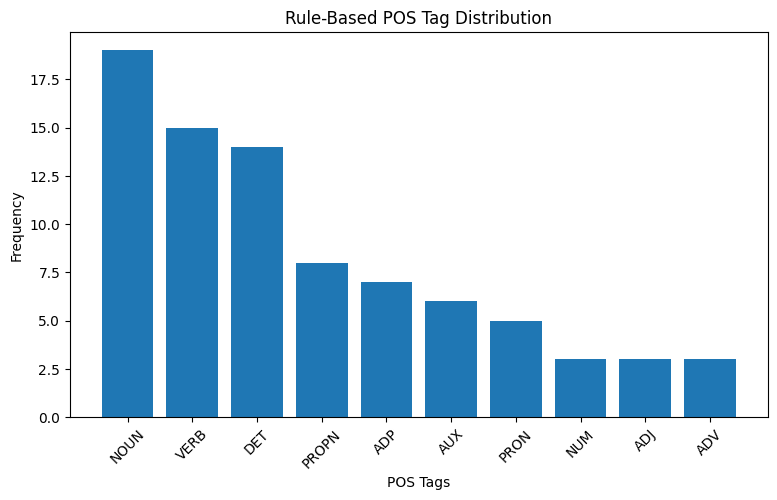


NEW SENTENCE TEST
Input: I want to book a bus ticket to Chennai
Output:
I : PRON
want : VERB
to : ADP
book : VERB
a : DET
bus : NOUN
ticket : NOUN
to : ADP
Chennai : PROPN

TASK 7 FINAL SUMMARY
Total Sentences: 15
Total Tagged Words: 83
Different POS Tags: 10

TASK 7 COMPLETED SUCCESSFULLY!


In [ ]:
# TASK 7: RULE-BASED POS TAGGING
# Public Transport Enquiry Helpline

import re
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

# --------------------------------------------------
# 1. CREATE TRANSPORT ENQUIRY SENTENCES
# --------------------------------------------------

sentences = [
    "I want to book two tickets",
    "What is the bus timing to Chennai",
    "The train arrives at the station",
    "Please cancel my ticket",
    "Is there a bus available today",
    "I need a seat to Bangalore",
    "When will the train leave",
    "The bus is running late",
    "Can I reserve a ticket online",
    "Tell me the fare to Hyderabad",
    "The passenger booked three seats",
    "Where is the nearest bus stop",
    "My train departs at six",
    "Please check the arrival time",
    "I want to travel tomorrow"
]

# --------------------------------------------------
# 2. DEFINE WORD DICTIONARIES
# --------------------------------------------------

pronouns = {
    "i", "we", "you", "he", "she", "they",
    "it", "me", "him", "her", "us", "them"
}

determiners = {
    "the", "a", "an", "this", "that", "my",
    "your", "our", "their"
}

auxiliaries = {
    "is", "am", "are", "was", "were",
    "will", "can", "could", "do", "does"
}

prepositions = {
    "at", "in", "on", "from", "with",
    "by", "for", "of", "to"
}

conjunctions = {
    "and", "or", "but", "because"
}

verbs = {
    "want", "book", "cancel", "arrive", "arrives",
    "need", "leave", "reserve", "tell", "check",
    "travel", "departs", "depart", "running",
    "booked", "reserve"
}

nouns = {
    "ticket", "tickets", "bus", "train", "timing",
    "station", "seat", "seats", "fare", "passenger",
    "stop", "arrival", "time"
}

adjectives = {
    "late", "available", "nearest", "early",
    "fast", "slow"
}

adverbs = {
    "today", "tomorrow", "online", "quickly"
}

numbers = {
    "one", "two", "three", "four", "five",
    "six", "seven", "eight", "nine", "ten"
}

# --------------------------------------------------
# 3. TOKENIZATION
# --------------------------------------------------

def tokenize(sentence):
    return re.findall(r"\b[\w]+\b|[^\w\s]", sentence)


# --------------------------------------------------
# 4. RULE-BASED POS TAGGING
# --------------------------------------------------

def pos_tag(words):

    tagged_words = []

    for i, word in enumerate(words):

        lower_word = word.lower()

        # Rule 1: Punctuation
        if re.fullmatch(r"[^\w\s]", word):
            tag = "PUNCT"

        # Rule 2: Pronouns
        elif lower_word in pronouns:
            tag = "PRON"

        # Rule 3: Determiners
        elif lower_word in determiners:
            tag = "DET"

        # Rule 4: Auxiliary verbs
        elif lower_word in auxiliaries:
            tag = "AUX"

        # Rule 5: Conjunctions
        elif lower_word in conjunctions:
            tag = "CCONJ"

        # Rule 6: Numbers
        elif lower_word.isdigit() or lower_word in numbers:
            tag = "NUM"

        # Rule 7: Prepositions
        elif lower_word in prepositions:
            tag = "ADP"

        # Rule 8: Adverbs
        elif lower_word in adverbs or lower_word.endswith("ly"):
            tag = "ADV"

        # Rule 9: Adjectives
        elif lower_word in adjectives or lower_word.endswith(("ous", "ful", "able", "ive")):
            tag = "ADJ"

        # Rule 10: Verbs
        elif lower_word in verbs:
            tag = "VERB"

        # Rule 11: Verb suffix rules
        elif lower_word.endswith(("ing", "ed")):
            tag = "VERB"

        # Rule 12: Proper nouns
        elif word[0].isupper():
            tag = "PROPN"

        # Rule 13: Nouns
        elif lower_word in nouns or lower_word.endswith(("tion", "ment", "ness")):
            tag = "NOUN"

        # Rule 14: Default
        else:
            tag = "NOUN"

        tagged_words.append((word, tag))

    return tagged_words


# --------------------------------------------------
# 5. APPLY POS TAGGING
# --------------------------------------------------

all_tagged_sentences = []

for sentence in sentences:

    words = tokenize(sentence)

    tagged = pos_tag(words)

    all_tagged_sentences.append(tagged)


# --------------------------------------------------
# 6. DISPLAY TAGGING RESULTS
# --------------------------------------------------

print("RULE-BASED POS TAGGING RESULTS\n")

for i, tagged in enumerate(all_tagged_sentences, start=1):

    result = " | ".join(
        [word + "/" + tag for word, tag in tagged]
    )

    print("Sentence", i, ":", result)


# --------------------------------------------------
# 7. CREATE DATAFRAME
# --------------------------------------------------

rows = []

for sentence, tagged in zip(sentences, all_tagged_sentences):

    for word, tag in tagged:

        rows.append({
            "Sentence": sentence,
            "Word": word,
            "POS Tag": tag
        })


df = pd.DataFrame(rows)

print("\nWORD-LEVEL POS TAGGING TABLE")

display(df)


# --------------------------------------------------
# 8. COUNT POS TAGS
# --------------------------------------------------

tag_counts = Counter()

for tagged in all_tagged_sentences:

    for word, tag in tagged:

        tag_counts[tag] += 1


tag_df = pd.DataFrame(
    tag_counts.items(),
    columns=["POS Tag", "Frequency"]
).sort_values(
    by="Frequency",
    ascending=False
)

print("\nPOS TAG FREQUENCY")

display(tag_df)


# --------------------------------------------------
# 9. VISUALIZE POS TAG DISTRIBUTION
# --------------------------------------------------

plt.figure(figsize=(9, 5))

plt.bar(
    tag_df["POS Tag"],
    tag_df["Frequency"]
)

plt.title("Rule-Based POS Tag Distribution")
plt.xlabel("POS Tags")
plt.ylabel("Frequency")

plt.xticks(rotation=45)

plt.show()


# --------------------------------------------------
# 10. TEST A NEW SENTENCE
# --------------------------------------------------

test_sentence = "I want to book a bus ticket to Chennai"

test_words = tokenize(test_sentence)

test_result = pos_tag(test_words)

print("\nNEW SENTENCE TEST")

print("Input:", test_sentence)

print("Output:")

for word, tag in test_result:
    print(word, ":", tag)


# --------------------------------------------------
# 11. FINAL SUMMARY
# --------------------------------------------------

print("\nTASK 7 FINAL SUMMARY")

print("Total Sentences:", len(sentences))
print("Total Tagged Words:", len(rows))
print("Different POS Tags:", len(tag_counts))

print("\nTASK 7 COMPLETED SUCCESSFULLY!")

HMM POS TAGGING RESULTS

Sentence 1
i : PRON
want : VERB
to : PART
book : VERB
a : DET
ticket : NOUN
to : PART
chennai : PROPN

Sentence 2
the : DET
train : NOUN
arrives : PART
today : PROPN

Sentence 3
can : AUX
i : PRON
reserve : VERB
a : DET
seat : NOUN
online : ADV

TAGGING EVALUATION


,Word,Actual Tag,Predicted Tag,Correct
0,i,PRON,PRON,True
1,want,VERB,VERB,True
2,to,PART,PART,True
3,book,VERB,VERB,True
4,a,DET,DET,True
5,ticket,NOUN,NOUN,True
6,to,PART,PART,True
7,chennai,PROPN,PROPN,True
8,the,DET,DET,True
9,train,NOUN,NOUN,True


Correct Predictions: 16
Total Words: 18
Tagging Accuracy: 88.89 %

TRAINING POS TAG FREQUENCY


,POS Tag,Frequency
4,NOUN,15
1,VERB,10
6,DET,10
0,PRON,7
5,AUX,6
11,ADV,4
10,ADJ,3
2,PART,3
8,PROPN,3
3,NUM,2


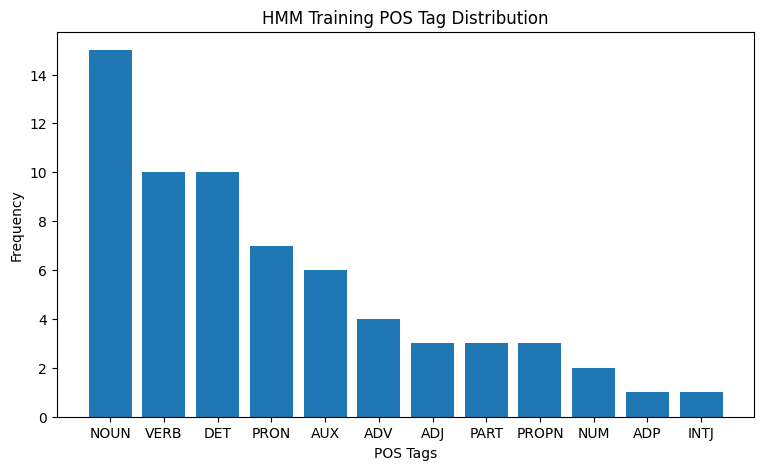


NEW SENTENCE TEST
Input: the train arrives at chennai
Predicted POS Tags:
the : DET
train : NOUN
arrives : VERB
at : ADP
chennai : PROPN

TASK 8 FINAL SUMMARY
Training Sentences: 12
Testing Sentences: 3
Number of POS Tags: 12
Vocabulary Size: 45
Tagging Accuracy: 88.89 %

TASK 8 COMPLETED SUCCESSFULLY!


In [ ]:
# TASK 8: HMM POS TAGGING AND VITERBI ALGORITHM
# Public Transport Enquiry Helpline

import re
import math
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter, defaultdict

# --------------------------------------------------
# 1. CREATE POS-TAGGED TRAINING DATA
# --------------------------------------------------

training_data = [
    [("i", "PRON"), ("want", "VERB"), ("to", "PART"),
     ("book", "VERB"), ("two", "NUM"), ("tickets", "NOUN")],

    [("what", "PRON"), ("is", "AUX"), ("the", "DET"),
     ("bus", "NOUN"), ("timing", "NOUN")],

    [("the", "DET"), ("train", "NOUN"), ("arrives", "VERB"),
     ("at", "ADP"), ("chennai", "PROPN")],

    [("please", "INTJ"), ("cancel", "VERB"),
     ("my", "PRON"), ("ticket", "NOUN")],

    [("is", "AUX"), ("there", "PRON"), ("a", "DET"),
     ("bus", "NOUN"), ("available", "ADJ"), ("today", "ADV")],

    [("i", "PRON"), ("need", "VERB"), ("a", "DET"),
     ("seat", "NOUN"), ("to", "PART"), ("bangalore", "PROPN")],

    [("when", "ADV"), ("will", "AUX"), ("the", "DET"),
     ("train", "NOUN"), ("leave", "VERB")],

    [("the", "DET"), ("bus", "NOUN"), ("is", "AUX"),
     ("running", "VERB"), ("late", "ADJ")],

    [("can", "AUX"), ("i", "PRON"), ("reserve", "VERB"),
     ("a", "DET"), ("ticket", "NOUN"), ("online", "ADV")],

    [("tell", "VERB"), ("me", "PRON"), ("the", "DET"),
     ("fare", "NOUN"), ("to", "PART"), ("hyderabad", "PROPN")],

    [("the", "DET"), ("passenger", "NOUN"),
     ("booked", "VERB"), ("three", "NUM"), ("seats", "NOUN")],

    [("where", "ADV"), ("is", "AUX"), ("the", "DET"),
     ("nearest", "ADJ"), ("bus", "NOUN"), ("stop", "NOUN")]
]

# --------------------------------------------------
# 2. PREPARE TEST DATA
# --------------------------------------------------

test_data = [
    [
        ("i", "PRON"), ("want", "VERB"), ("to", "PART"),
        ("book", "VERB"), ("a", "DET"), ("ticket", "NOUN"),
        ("to", "PART"), ("chennai", "PROPN")
    ],

    [
        ("the", "DET"), ("train", "NOUN"),
        ("arrives", "VERB"), ("today", "ADV")
    ],

    [
        ("can", "AUX"), ("i", "PRON"),
        ("reserve", "VERB"), ("a", "DET"),
        ("seat", "NOUN"), ("online", "ADV")
    ]
]

# --------------------------------------------------
# 3. BUILD HMM COUNTS
# --------------------------------------------------

transition_counts = defaultdict(Counter)
emission_counts = defaultdict(Counter)

tag_counts = Counter()
vocabulary = set()
tags = set()

for sentence in training_data:

    previous_tag = "<START>"

    for word, tag in sentence:

        vocabulary.add(word)
        tags.add(tag)

        transition_counts[previous_tag][tag] += 1
        emission_counts[tag][word] += 1

        tag_counts[tag] += 1

        previous_tag = tag

    transition_counts[previous_tag]["<END>"] += 1


# --------------------------------------------------
# 4. CALCULATE TRANSITION PROBABILITY
# --------------------------------------------------

def transition_probability(previous_tag, current_tag):

    possible_tags = len(tags) + 1

    count = transition_counts[previous_tag][current_tag]
    total = sum(transition_counts[previous_tag].values())

    return (count + 1) / (total + possible_tags)


# --------------------------------------------------
# 5. CALCULATE EMISSION PROBABILITY
# --------------------------------------------------

def emission_probability(tag, word):

    count = emission_counts[tag][word]
    total = tag_counts[tag]

    return (count + 1) / (total + len(vocabulary) + 1)


# --------------------------------------------------
# 6. IMPLEMENT VITERBI ALGORITHM
# --------------------------------------------------

def viterbi(words):

    words = [word.lower() for word in words]

    tag_list = sorted(tags)

    # Store probabilities and previous tags
    V = [{}]
    backpointer = [{}]

    # Initial probabilities
    for tag in tag_list:

        trans = transition_probability("<START>", tag)
        emit = emission_probability(tag, words[0])

        V[0][tag] = math.log(trans) + math.log(emit)
        backpointer[0][tag] = None

    # Process remaining words
    for t in range(1, len(words)):

        V.append({})
        backpointer.append({})

        for current_tag in tag_list:

            best_score = float("-inf")
            best_previous_tag = None

            for previous_tag in tag_list:

                score = (
                    V[t-1][previous_tag]
                    + math.log(
                        transition_probability(
                            previous_tag, current_tag
                        )
                    )
                    + math.log(
                        emission_probability(
                            current_tag, words[t]
                        )
                    )
                )

                if score > best_score:

                    best_score = score
                    best_previous_tag = previous_tag

            V[t][current_tag] = best_score
            backpointer[t][current_tag] = best_previous_tag

    # Find the best final tag
    best_final_tag = max(
        tag_list,
        key=lambda tag: (
            V[-1][tag]
            + math.log(
                transition_probability(tag, "<END>")
            )
        )
    )

    # Backtracking
    best_sequence = [best_final_tag]

    for t in range(len(words) - 1, 0, -1):

        best_sequence.insert(
            0,
            backpointer[t][best_sequence[0]]
        )

    return list(zip(words, best_sequence))


# --------------------------------------------------
# 7. TEST VITERBI TAGGING
# --------------------------------------------------

print("HMM POS TAGGING RESULTS\n")

for i, sentence in enumerate(test_data, start=1):

    words = [word for word, tag in sentence]

    predicted = viterbi(words)

    print("Sentence", i)

    for word, tag in predicted:
        print(word, ":", tag)

    print()


# --------------------------------------------------
# 8. EVALUATE TAGGING ACCURACY
# --------------------------------------------------

correct = 0
total = 0

evaluation_results = []

for sentence in test_data:

    words = [word for word, tag in sentence]
    actual_tags = [tag for word, tag in sentence]

    predicted = viterbi(words)
    predicted_tags = [tag for word, tag in predicted]

    for word, actual, predicted_tag in zip(
        words, actual_tags, predicted_tags
    ):

        if actual == predicted_tag:
            correct += 1

        total += 1

        evaluation_results.append({
            "Word": word,
            "Actual Tag": actual,
            "Predicted Tag": predicted_tag,
            "Correct": actual == predicted_tag
        })


accuracy = (correct / total) * 100 if total else 0

print("TAGGING EVALUATION")
display(pd.DataFrame(evaluation_results))

print("Correct Predictions:", correct)
print("Total Words:", total)
print("Tagging Accuracy:", round(accuracy, 2), "%")


# --------------------------------------------------
# 9. DISPLAY POS TAG DISTRIBUTION
# --------------------------------------------------

tag_frequency = pd.DataFrame(
    tag_counts.items(),
    columns=["POS Tag", "Frequency"]
).sort_values(
    by="Frequency",
    ascending=False
)

print("\nTRAINING POS TAG FREQUENCY")
display(tag_frequency)

plt.figure(figsize=(9, 5))

plt.bar(
    tag_frequency["POS Tag"],
    tag_frequency["Frequency"]
)

plt.title("HMM Training POS Tag Distribution")
plt.xlabel("POS Tags")
plt.ylabel("Frequency")

plt.show()


# --------------------------------------------------
# 10. TEST A NEW SENTENCE
# --------------------------------------------------

new_sentence = "the train arrives at chennai"

new_words = re.findall(
    r"\b[\w]+\b",
    new_sentence.lower()
)

new_result = viterbi(new_words)

print("\nNEW SENTENCE TEST")
print("Input:", new_sentence)
print("Predicted POS Tags:")

for word, tag in new_result:
    print(word, ":", tag)


# --------------------------------------------------
# 11. FINAL SUMMARY
# --------------------------------------------------

print("\nTASK 8 FINAL SUMMARY")

print("Training Sentences:", len(training_data))
print("Testing Sentences:", len(test_data))
print("Number of POS Tags:", len(tags))
print("Vocabulary Size:", len(vocabulary))
print("Tagging Accuracy:", round(accuracy, 2), "%")

print("\nTASK 8 COMPLETED SUCCESSFULLY!")

Initial Unigram Tagger Created Successfully
Brill Templates:
[Template(Pos([-1])), Template(Pos([1])), Template(Pos([-2])), Template(Pos([2])), Template(Pos([-2, -1])), Template(Pos([1, 2])), Template(Pos([-1, 1]))]

BRILL TAGGER TRAINED SUCCESSFULLY

LEARNED BRILL RULES

Total Rules Learned: 0

BRILL POS TAGGING RESULTS

Sentence 1
i : PRON
want : VERB
to : PART
book : VERB
a : DET
ticket : NOUN

Sentence 2
the : DET
bus : NOUN
arrives : VERB
today : ADV

Sentence 3
please : INTJ
reserve : VERB
three : NUM
seats : NOUN

Sentence 4
the : DET
train : NOUN
is : AUX
late : ADJ

Sentence 5
i : PRON
need : VERB
a : DET
ticket : NOUN
to : PART
madurai : PROPN

EVALUATION RESULTS


,Word,Actual Tag,Predicted Tag,Correct
0,i,PRON,PRON,True
1,want,VERB,VERB,True
2,to,PART,PART,True
3,book,VERB,VERB,True
4,a,DET,DET,True
5,ticket,NOUN,NOUN,True
6,the,DET,DET,True
7,bus,NOUN,NOUN,True
8,arrives,VERB,VERB,True
9,today,ADV,ADV,True


Brill Tagging Accuracy: 100.0 %

TAGGER COMPARISON


,Tagger,Accuracy (%)
0,Unigram Tagger,100.0
1,Brill Tagger,100.0


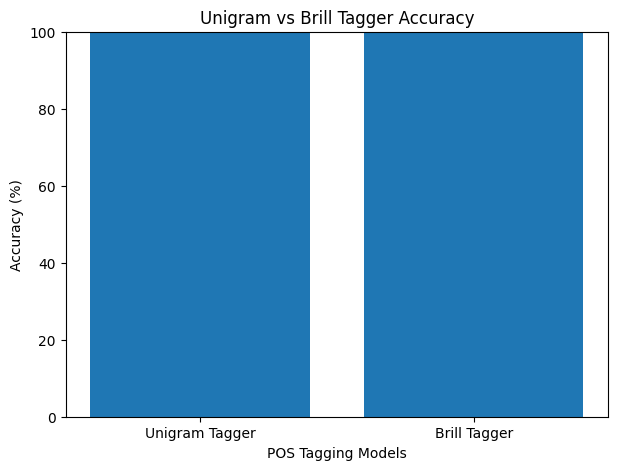


NEW SENTENCE TEST
Input: i want to reserve a bus ticket today
i : PRON
want : VERB
to : PART
reserve : VERB
a : DET
bus : NOUN
ticket : NOUN
today : ADV

TASK 9 FINAL SUMMARY
Training Sentences: 20
Testing Sentences: 5
Brill Rules Learned: 0
Unigram Accuracy: 100.0 %
Brill Accuracy: 100.0 %

TASK 9 COMPLETED SUCCESSFULLY!


In [ ]:
# TASK 9: BRILL POS TAGGING
# Public Transport Enquiry Helpline

# --------------------------------------------------
# 1. INSTALL AND IMPORT LIBRARIES
# --------------------------------------------------

!pip -q install nltk

import nltk
import pandas as pd
import matplotlib.pyplot as plt

from nltk.tag import UnigramTagger, DefaultTagger
from nltk.tag.brill import Pos
from nltk.tag.brill import Template
from nltk.tag.brill_trainer import BrillTaggerTrainer
from sklearn.metrics import accuracy_score


# --------------------------------------------------
# 2. CREATE POS-TAGGED TRAINING DATA
# --------------------------------------------------

train_data = [
    [("i", "PRON"), ("want", "VERB"), ("to", "PART"),
     ("book", "VERB"), ("two", "NUM"), ("tickets", "NOUN")],

    [("what", "PRON"), ("is", "AUX"), ("the", "DET"),
     ("bus", "NOUN"), ("timing", "NOUN")],

    [("the", "DET"), ("train", "NOUN"), ("arrives", "VERB"),
     ("at", "ADP"), ("chennai", "PROPN")],

    [("please", "INTJ"), ("cancel", "VERB"),
     ("my", "PRON"), ("ticket", "NOUN")],

    [("is", "AUX"), ("there", "PRON"), ("a", "DET"),
     ("bus", "NOUN"), ("available", "ADJ"), ("today", "ADV")],

    [("i", "PRON"), ("need", "VERB"), ("a", "DET"),
     ("seat", "NOUN"), ("to", "PART"), ("bangalore", "PROPN")],

    [("when", "ADV"), ("will", "AUX"), ("the", "DET"),
     ("train", "NOUN"), ("leave", "VERB")],

    [("the", "DET"), ("bus", "NOUN"), ("is", "AUX"),
     ("running", "VERB"), ("late", "ADJ")],

    [("can", "AUX"), ("i", "PRON"), ("reserve", "VERB"),
     ("a", "DET"), ("ticket", "NOUN"), ("online", "ADV")],

    [("tell", "VERB"), ("me", "PRON"), ("the", "DET"),
     ("fare", "NOUN"), ("to", "PART"), ("hyderabad", "PROPN")],

    [("the", "DET"), ("passenger", "NOUN"),
     ("booked", "VERB"), ("three", "NUM"), ("seats", "NOUN")],

    [("where", "ADV"), ("is", "AUX"), ("the", "DET"),
     ("nearest", "ADJ"), ("bus", "NOUN"), ("stop", "NOUN")],

    [("my", "PRON"), ("ticket", "NOUN"), ("is", "AUX"),
     ("confirmed", "VERB")],

    [("show", "VERB"), ("the", "DET"), ("departure", "NOUN"),
     ("time", "NOUN")],

    [("we", "PRON"), ("need", "VERB"), ("four", "NUM"),
     ("seats", "NOUN"), ("today", "ADV")],

    [("the", "DET"), ("bus", "NOUN"), ("reached", "VERB"),
     ("madurai", "PROPN")],

    [("book", "NOUN"), ("a", "DET"), ("ticket", "NOUN")],

    [("i", "PRON"), ("can", "AUX"), ("book", "VERB"),
     ("online", "ADV")],

    [("the", "DET"), ("train", "NOUN"), ("is", "AUX"),
     ("late", "ADJ")],

    [("reserve", "VERB"), ("two", "NUM"),
     ("seats", "NOUN"), ("please", "INTJ")]
]


# --------------------------------------------------
# 3. CREATE TEST DATA
# --------------------------------------------------

test_data = [
    [("i", "PRON"), ("want", "VERB"), ("to", "PART"),
     ("book", "VERB"), ("a", "DET"), ("ticket", "NOUN")],

    [("the", "DET"), ("bus", "NOUN"),
     ("arrives", "VERB"), ("today", "ADV")],

    [("please", "INTJ"), ("reserve", "VERB"),
     ("three", "NUM"), ("seats", "NOUN")],

    [("the", "DET"), ("train", "NOUN"),
     ("is", "AUX"), ("late", "ADJ")],

    [("i", "PRON"), ("need", "VERB"),
     ("a", "DET"), ("ticket", "NOUN"),
     ("to", "PART"), ("madurai", "PROPN")]
]


# --------------------------------------------------
# 4. CREATE INITIAL TAGGER
# --------------------------------------------------

default_tagger = DefaultTagger("NOUN")

initial_tagger = UnigramTagger(
    train_data,
    backoff=default_tagger
)

print("Initial Unigram Tagger Created Successfully")


# --------------------------------------------------
# 5. DEFINE BRILL TEMPLATES
# --------------------------------------------------

templates = [
    Template(Pos([-1])),
    Template(Pos([1])),
    Template(Pos([-2])),
    Template(Pos([2])),
    Template(Pos([-2, -1])),
    Template(Pos([1, 2])),
    Template(Pos([-1, 1]))
]

print("Brill Templates:")
print(templates)


# --------------------------------------------------
# 6. TRAIN BRILL TAGGER
# --------------------------------------------------

trainer = BrillTaggerTrainer(
    initial_tagger,
    templates,
    trace=0
)

brill_tagger = trainer.train(
    train_data,
    max_rules=50,
    min_score=1
)

print("\nBRILL TAGGER TRAINED SUCCESSFULLY")


# --------------------------------------------------
# 7. DISPLAY LEARNED RULES
# --------------------------------------------------

print("\nLEARNED BRILL RULES")

rules = brill_tagger.rules()

for i, rule in enumerate(rules, start=1):
    print(f"Rule {i}: {rule}")

print("\nTotal Rules Learned:", len(rules))


# --------------------------------------------------
# 8. TEST BRILL TAGGER
# --------------------------------------------------

print("\nBRILL POS TAGGING RESULTS")

for i, sentence in enumerate(test_data, start=1):

    words = [word for word, tag in sentence]

    predicted = brill_tagger.tag(words)

    print("\nSentence", i)

    for word, tag in predicted:
        print(word, ":", tag)


# --------------------------------------------------
# 9. EVALUATE TAGGING ACCURACY
# --------------------------------------------------

actual_tags = []
predicted_tags = []

evaluation_results = []

for sentence in test_data:

    words = [word for word, tag in sentence]

    actual = [tag for word, tag in sentence]

    predicted = [
        tag for word, tag in brill_tagger.tag(words)
    ]

    for word, actual_tag, predicted_tag in zip(
        words, actual, predicted
    ):

        actual_tags.append(actual_tag)
        predicted_tags.append(predicted_tag)

        evaluation_results.append({
            "Word": word,
            "Actual Tag": actual_tag,
            "Predicted Tag": predicted_tag,
            "Correct": actual_tag == predicted_tag
        })


accuracy = accuracy_score(
    actual_tags,
    predicted_tags
) * 100

print("\nEVALUATION RESULTS")

display(pd.DataFrame(evaluation_results))

print("Brill Tagging Accuracy:", round(accuracy, 2), "%")


# --------------------------------------------------
# 10. COMPARE UNIGRAM AND BRILL TAGGERS
# --------------------------------------------------

unigram_predictions = []
brill_predictions = []
actual_labels = []

for sentence in test_data:

    words = [word for word, tag in sentence]

    actual = [tag for word, tag in sentence]

    unigram_output = [
        tag for word, tag in initial_tagger.tag(words)
    ]

    brill_output = [
        tag for word, tag in brill_tagger.tag(words)
    ]

    actual_labels.extend(actual)
    unigram_predictions.extend(unigram_output)
    brill_predictions.extend(brill_output)


unigram_accuracy = accuracy_score(
    actual_labels,
    unigram_predictions
) * 100

brill_accuracy = accuracy_score(
    actual_labels,
    brill_predictions
) * 100


comparison = pd.DataFrame({
    "Tagger": ["Unigram Tagger", "Brill Tagger"],
    "Accuracy (%)": [
        round(unigram_accuracy, 2),
        round(brill_accuracy, 2)
    ]
})

print("\nTAGGER COMPARISON")

display(comparison)


# --------------------------------------------------
# 11. VISUALIZE ACCURACY
# --------------------------------------------------

plt.figure(figsize=(7, 5))

plt.bar(
    comparison["Tagger"],
    comparison["Accuracy (%)"]
)

plt.title("Unigram vs Brill Tagger Accuracy")
plt.xlabel("POS Tagging Models")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

plt.show()


# --------------------------------------------------
# 12. TEST A NEW SENTENCE
# --------------------------------------------------

new_sentence = "i want to reserve a bus ticket today"

new_words = new_sentence.lower().split()

new_result = brill_tagger.tag(new_words)

print("\nNEW SENTENCE TEST")
print("Input:", new_sentence)

for word, tag in new_result:
    print(word, ":", tag)


# --------------------------------------------------
# 13. FINAL SUMMARY
# --------------------------------------------------

print("\nTASK 9 FINAL SUMMARY")

print("Training Sentences:", len(train_data))
print("Testing Sentences:", len(test_data))
print("Brill Rules Learned:", len(rules))
print("Unigram Accuracy:", round(unigram_accuracy, 2), "%")
print("Brill Accuracy:", round(brill_accuracy, 2), "%")

print("\nTASK 9 COMPLETED SUCCESSFULLY!")

TRAINING SENTENCES: 16000
DEVELOPMENT SENTENCES: 2000
TEST SENTENCES: 2000

N-GRAM MODEL TRAINED
Training Time: 0.6191 seconds
Vocabulary Size: 49
Approximate N-gram Model Memory: 30.77 KB

LANGUAGE MODEL PERPLEXITY
unigram : 42.0969
laplace : 1.9154
add_k : 1.8851
good_turing : 1.8499
backoff : 1.9154
interpolation : 2.5822

TAGGER PERFORMANCE

Tagger: Rule-Based
Accuracy: 59.09 %
Tagging Speed: 316660.67 tokens/second
Testing Time: 7e-05 seconds

Tagger: HMM
Accuracy: 13.64 %
Tagging Speed: 3509.58 tokens/second
Testing Time: 0.00627 seconds

Tagger: Brill
Accuracy: 54.55 %
Tagging Speed: 253640.32 tokens/second
Testing Time: 9e-05 seconds

TRAINING TIME COMPARISON
N-gram : 0.61906 seconds
HMM : 0.00062 seconds
Brill : 0.00167 seconds
Rule-Based : 0 seconds

TASK 2 ZERO-PROBABILITY TEST
Unseen Bigram: ('to', 'airport')
Unsmoothed Probability: 0.0
Smoothed Trigram Probability: 0.02040816326530612

TASK 4 INTERPOLATION WEIGHTS
Unigram Lambda: 0.2
Bigram Lambda: 0.3
Trigram Lambda: 0.5


/usr/local/lib/python3.13/dist-packages/nltk/tag/hmm.py:333: RuntimeWarning: overflow encountered in cast
  X[i, j] = self._transitions[si].logprob(self._states[j])
/usr/local/lib/python3.13/dist-packages/nltk/tag/hmm.py:335: RuntimeWarning: overflow encountered in cast
  O[i, k] = self._output_logprob(si, self._symbols[k])
/usr/local/lib/python3.13/dist-packages/nltk/tag/hmm.py:331: RuntimeWarning: overflow encountered in cast
  P[i] = self._priors.logprob(si)
/usr/local/lib/python3.13/dist-packages/nltk/tag/hmm.py:363: RuntimeWarning: overflow encountered in cast
  O[i, k] = self._output_logprob(si, self._symbols[k])


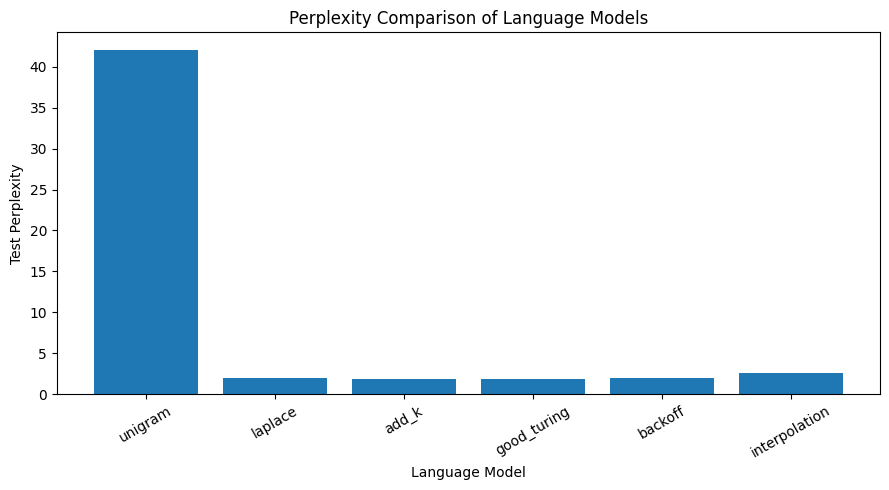

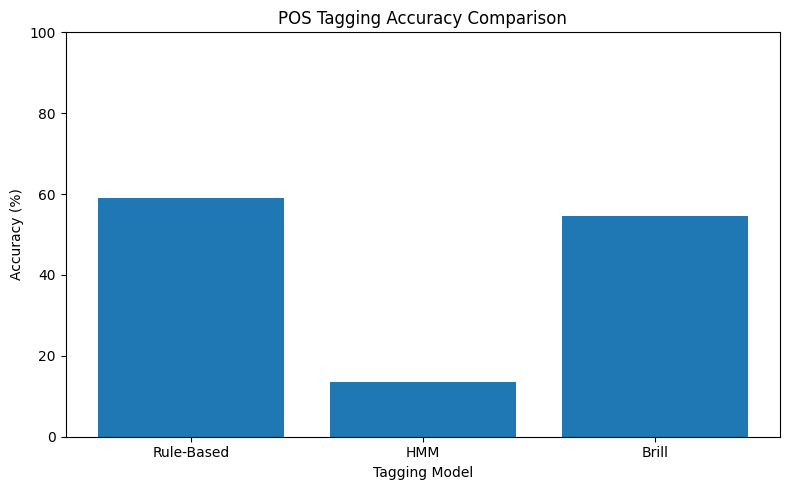


TASK 10 FINAL RESULTS
Total Corpus: 20000
Training Data: 16000
Development Data: 2000
Testing Data: 2000

Best N-gram Model: good_turing
Best Tagger: Rule-Based

TASK 10 COMPLETED SUCCESSFULLY!


In [ ]:
# TASK 10: IMPLEMENT AND TEST THE MODELS
# N-gram Language Models + Rule-Based, HMM and Brill Taggers

!pip -q install nltk

import re
import sys
import time
import math
import random
import pickle
import nltk
import matplotlib.pyplot as plt

from collections import Counter, defaultdict
from nltk.util import ngrams
from nltk.tag import UnigramTagger, DefaultTagger
from nltk.tag.brill import Pos, Word, Template
from nltk.tag.brill_trainer import BrillTaggerTrainer
from nltk.tag.hmm import HiddenMarkovModelTrainer

random.seed(42)

# ==================================================
# 1. CREATE TRANSPORT ENQUIRY CORPUS
# ==================================================

destinations = [
    "chennai", "vellore", "madurai", "coimbatore",
    "bangalore", "hyderabad", "salem", "trichy",
    "tirupati", "kanchipuram"
]

templates = [
    "i want to book two tickets to {}",
    "what is the bus timing to {}",
    "tell me the train fare to {}",
    "when does the {} leave for {}",
    "i want to cancel my ticket",
    "is there a {} available to {}",
    "what is the return ticket fare to {}",
    "please check the next {} to {}",
    "how can i reserve a seat to {}",
    "when will the train arrive at {}"
]

corpus = []

for _ in range(20000):

    template = random.choice(templates)

    if template.count("{}") == 2:
        sentence = template.format(
            random.choice(["bus", "train", "metro"]),
            random.choice(destinations)
        )

    elif template.count("{}") == 1:
        sentence = template.format(random.choice(destinations))

    else:
        sentence = template

    corpus.append(sentence.lower())


def tokenize(sentence):
    return re.findall(r"\b[\w]+\b", sentence.lower())


# ==================================================
# 2. SPLIT DATA INTO TRAIN, DEVELOPMENT AND TEST
# ==================================================

random.shuffle(corpus)

n = len(corpus)

train_data = corpus[:int(0.8*n)]
dev_data = corpus[int(0.8*n):int(0.9*n)]
test_data = corpus[int(0.9*n):]

print("TRAINING SENTENCES:", len(train_data))
print("DEVELOPMENT SENTENCES:", len(dev_data))
print("TEST SENTENCES:", len(test_data))


# ==================================================
# 3. BUILD N-GRAM MODELS
# ==================================================

class NgramModel:

    def __init__(self, sentences):

        self.uni = Counter()
        self.bi = Counter()
        self.tri = Counter()

        self.context1 = Counter()
        self.context2 = Counter()

        self.vocab = set()

        for sentence in sentences:

            words = (
                ["<s>", "<s>"] +
                tokenize(sentence) +
                ["</s>"]
            )

            self.uni.update(ngrams(words, 1))
            self.bi.update(ngrams(words, 2))
            self.tri.update(ngrams(words, 3))

        for (w1, w2), count in self.bi.items():
            self.context1[w1] += count

        for (w1, w2, w3), count in self.tri.items():
            self.context2[(w1, w2)] += count

        self.vocab = {w[0] for w in self.uni}
        self.V = len(self.vocab)
        self.total = sum(self.uni.values())

        self.bigram_contexts = defaultdict(Counter)
        self.trigram_contexts = defaultdict(Counter)

        for (w1, w2), count in self.bi.items():
            self.bigram_contexts[w1][w2] = count

        for (w1, w2, w3), count in self.tri.items():
            self.trigram_contexts[(w1, w2)][w3] = count

    # ----------------------------------------------
    # UNIGRAM PROBABILITY
    # ----------------------------------------------

    def unigram(self, word):

        return (
            self.uni[(word,)] + 1
        ) / (self.total + self.V)

    # ----------------------------------------------
    # LAPLACE SMOOTHING
    # ----------------------------------------------

    def laplace(self, context, word, order):

        if order == 2:

            count = self.bi[(context[-1], word)]
            total = self.context1[context[-1]]

        else:

            count = self.tri[
                (context[-2], context[-1], word)
            ]

            total = self.context2[
                (context[-2], context[-1])
            ]

        return (count + 1) / (total + self.V)

    # ----------------------------------------------
    # ADD-K SMOOTHING
    # ----------------------------------------------

    def add_k(self, context, word, order, k=0.5):

        if order == 2:

            count = self.bi[(context[-1], word)]
            total = self.context1[context[-1]]

        else:

            count = self.tri[
                (context[-2], context[-1], word)
            ]

            total = self.context2[
                (context[-2], context[-1])
            ]

        return (count + k) / (total + k*self.V)

    # ----------------------------------------------
    # GOOD-TURING DISCOUNTING
    # ----------------------------------------------

    def good_turing(self, context, word, order):

        if order == 2:
            counts = self.bigram_contexts[context[-1]]
        else:
            counts = self.trigram_contexts[
                (context[-2], context[-1])
            ]

        total = sum(counts.values())

        if total == 0:
            return self.unigram(word)

        count = counts.get(word, 0)

        # Count-of-counts for the selected context
        frequency = Counter(counts.values())

        n1 = frequency.get(1, 0)
        unseen = max(self.V - len(counts), 1)

        if count == 0:
            return max(n1 / (total * unseen), 1e-12)

        n_count = frequency.get(count, 0)
        n_next = frequency.get(count + 1, 0)

        if n_count == 0 or n_next == 0:
            adjusted = count
        else:
            adjusted = (count + 1) * n_next / n_count

        return max(adjusted / total, 1e-12)

    # ----------------------------------------------
    # BACKOFF MODEL
    # ----------------------------------------------

    def backoff(self, w1, w2, w3):

        if self.tri[(w1, w2, w3)] > 0:
            return self.laplace((w1, w2), w3, 3)

        if self.bi[(w2, w3)] > 0:
            return self.laplace((w2,), w3, 2)

        return self.unigram(w3)

    # ----------------------------------------------
    # INTERPOLATION MODEL
    # ----------------------------------------------

    def interpolation(self, w1, w2, w3):

        p1 = self.unigram(w3)
        p2 = self.laplace((w2,), w3, 2)
        p3 = self.laplace((w1, w2), w3, 3)

        # Fixed demonstration weights
        return 0.2*p1 + 0.3*p2 + 0.5*p3

    # ----------------------------------------------
    # CALCULATE PERPLEXITY
    # ----------------------------------------------

    def perplexity(self, sentences, method="interpolation"):

        log_probability = 0
        total_words = 0

        for sentence in sentences:

            words = (
                ["<s>", "<s>"] +
                tokenize(sentence) +
                ["</s>"]
            )

            for i in range(2, len(words)):

                w1, w2, w3 = words[i-2:i+1]

                if method == "unigram":
                    p = self.unigram(w3)

                elif method == "laplace":
                    p = self.laplace((w1, w2), w3, 3)

                elif method == "add_k":
                    p = self.add_k((w1, w2), w3, 3)

                elif method == "good_turing":
                    p = self.good_turing((w1, w2), w3, 3)

                elif method == "backoff":
                    p = self.backoff(w1, w2, w3)

                else:
                    p = self.interpolation(w1, w2, w3)

                log_probability += math.log(max(p, 1e-12))
                total_words += 1

        return math.exp(-log_probability / total_words)


# ==================================================
# 4. TRAIN N-GRAM MODEL AND MEASURE TIME
# ==================================================

start = time.perf_counter()

lm = NgramModel(train_data)

ngram_training_time = time.perf_counter() - start

print("\nN-GRAM MODEL TRAINED")
print("Training Time:", round(ngram_training_time, 4), "seconds")
print("Vocabulary Size:", lm.V)


# ==================================================
# 5. MEASURE N-GRAM MODEL MEMORY
# ==================================================

ngram_memory = sys.getsizeof(lm.__dict__)

for value in lm.__dict__.values():
    ngram_memory += sys.getsizeof(value)

print(
    "Approximate N-gram Model Memory:",
    round(ngram_memory / 1024, 2),
    "KB"
)


# ==================================================
# 6. TEST ALL LANGUAGE MODELS
# ==================================================

methods = [
    "unigram",
    "laplace",
    "add_k",
    "good_turing",
    "backoff",
    "interpolation"
]

perplexity_results = {}

print("\nLANGUAGE MODEL PERPLEXITY")

for method in methods:

    pp = lm.perplexity(test_data, method)

    perplexity_results[method] = pp

    print(method, ":", round(pp, 4))


# ==================================================
# 7. CREATE MANUALLY TAGGED TRAINING DATA
# ==================================================

tagged_sentences = [

    [("i","PRON"),("want","VERB"),("to","PART"),
     ("book","VERB"),("two","NUM"),("tickets","NOUN"),
     ("to","PART"),("vellore","PROPN")],

    [("what","PRON"),("is","AUX"),("the","DET"),
     ("bus","NOUN"),("timing","NOUN"),("today","ADV")],

    [("the","DET"),("train","NOUN"),("arrives","VERB"),
     ("at","ADP"),("chennai","PROPN")],

    [("please","INTJ"),("cancel","VERB"),
     ("my","PRON"),("ticket","NOUN")],

    [("is","AUX"),("there","PRON"),("a","DET"),
     ("bus","NOUN"),("available","ADJ"),("today","ADV")],

    [("i","PRON"),("need","VERB"),("a","DET"),
     ("seat","NOUN"),("to","PART"),("bangalore","PROPN")],

    [("when","ADV"),("will","AUX"),("the","DET"),
     ("train","NOUN"),("leave","VERB")],

    [("the","DET"),("bus","NOUN"),("is","AUX"),
     ("running","VERB"),("late","ADJ")],

    [("can","AUX"),("i","PRON"),("reserve","VERB"),
     ("a","DET"),("ticket","NOUN"),("online","ADV")],

    [("tell","VERB"),("me","PRON"),("the","DET"),
     ("fare","NOUN"),("to","PART"),("hyderabad","PROPN")],

    [("the","DET"),("passenger","NOUN"),
     ("booked","VERB"),("three","NUM"),("seats","NOUN")],

    [("where","ADV"),("is","AUX"),("the","DET"),
     ("nearest","ADJ"),("bus","NOUN"),("stop","NOUN")],

    [("my","PRON"),("ticket","NOUN"),("is","AUX"),
     ("confirmed","VERB")],

    [("show","VERB"),("the","DET"),
     ("departure","NOUN"),("time","NOUN")],

    [("we","PRON"),("need","VERB"),
     ("four","NUM"),("seats","NOUN"),("today","ADV")],

    [("the","DET"),("bus","NOUN"),
     ("reached","VERB"),("madurai","PROPN")],

    [("book","NOUN"),("a","DET"),("ticket","NOUN")],

    [("i","PRON"),("can","AUX"),
     ("book","VERB"),("online","ADV")],

    [("the","DET"),("train","NOUN"),
     ("is","AUX"),("late","ADJ")],

    [("reserve","VERB"),("two","NUM"),
     ("seats","NOUN"),("please","INTJ")]

]

random.shuffle(tagged_sentences)

tag_split = int(0.8 * len(tagged_sentences))

tag_train = tagged_sentences[:tag_split]
tag_test = tagged_sentences[tag_split:]


# ==================================================
# 8. RULE-BASED TAGGER
# ==================================================

word_dictionary = {}

for sentence in tag_train:
    for word, tag in sentence:
        word_dictionary[word] = tag


def rule_tagger(words):

    result = []

    for word in words:

        w = word.lower()

        if w in word_dictionary:
            tag = word_dictionary[w]

        elif w.endswith("ing") or w.endswith("ed"):
            tag = "VERB"

        elif w.endswith("ly"):
            tag = "ADV"

        elif w in ["the", "a", "an"]:
            tag = "DET"

        elif w in ["i", "we", "you", "he", "she", "they"]:
            tag = "PRON"

        elif w in ["is", "am", "are", "will", "can"]:
            tag = "AUX"

        elif w in destinations:
            tag = "PROPN"

        else:
            tag = "NOUN"

        result.append((word, tag))

    return result


# ==================================================
# 9. TRAIN HMM TAGGER
# ==================================================

start = time.perf_counter()

hmm_trainer = HiddenMarkovModelTrainer()

hmm_tagger = hmm_trainer.train_supervised(tag_train)

hmm_training_time = time.perf_counter() - start


# ==================================================
# 10. TRAIN BRILL TAGGER
# ==================================================

start = time.perf_counter()

initial_tagger = UnigramTagger(
    tag_train,
    backoff=DefaultTagger("NOUN")
)

brill_templates = [
    Template(Pos([-1])),
    Template(Pos([1])),
    Template(Word([-1])),
    Template(Word([1])),
    Template(Pos([-2])),
    Template(Pos([2]))
]

brill_trainer = BrillTaggerTrainer(
    initial_tagger,
    brill_templates,
    trace=0
)

brill_tagger = brill_trainer.train(
    tag_train,
    max_rules=20,
    min_score=1
)

brill_training_time = time.perf_counter() - start


# ==================================================
# 11. EVALUATE TAGGING ACCURACY
# ==================================================

def evaluate_tagger(tagger_name):

    correct = 0
    total = 0

    start = time.perf_counter()

    for sentence in tag_test:

        words = [word for word, tag in sentence]
        actual = [tag for word, tag in sentence]

        if tagger_name == "Rule-Based":
            predicted = [
                tag for word, tag in rule_tagger(words)
            ]

        elif tagger_name == "HMM":
            predicted = [
                tag for word, tag in hmm_tagger.tag(words)
            ]

        else:
            predicted = [
                tag for word, tag in brill_tagger.tag(words)
            ]

        for a, p in zip(actual, predicted):

            if a == p:
                correct += 1

            total += 1

    elapsed = time.perf_counter() - start

    accuracy = 100 * correct / total if total else 0

    speed = total / elapsed if elapsed > 0 else 0

    return accuracy, speed, elapsed


taggers = ["Rule-Based", "HMM", "Brill"]

tagging_results = {}

for name in taggers:

    tagging_results[name] = evaluate_tagger(name)


# ==================================================
# 12. MODEL PERFORMANCE TABLE
# ==================================================

print("\nTAGGER PERFORMANCE")

for name, result in tagging_results.items():

    accuracy, speed, elapsed = result

    print("\nTagger:", name)
    print("Accuracy:", round(accuracy, 2), "%")
    print("Tagging Speed:", round(speed, 2), "tokens/second")
    print("Testing Time:", round(elapsed, 5), "seconds")


# ==================================================
# 13. TAGGING TRAINING TIME TABLE
# ==================================================

training_times = {
    "N-gram": ngram_training_time,
    "HMM": hmm_training_time,
    "Brill": brill_training_time,
    "Rule-Based": 0
}

print("\nTRAINING TIME COMPARISON")

for name, value in training_times.items():

    print(name, ":", round(value, 5), "seconds")


# ==================================================
# 14. CHECK ZERO-PROBABILITY CASE FROM TASK 2
# ==================================================

print("\nTASK 2 ZERO-PROBABILITY TEST")

unseen_bigram = ("to", "airport")

unsmoothed_probability = (
    lm.bi[unseen_bigram] / lm.context1["to"]
    if lm.context1["to"] > 0 else 0
)

smoothed_probability = lm.laplace(
    ("<s>", "to"), "airport", 3
)

print("Unseen Bigram:", unseen_bigram)
print("Unsmoothed Probability:", unsmoothed_probability)
print("Smoothed Trigram Probability:", smoothed_probability)


# ==================================================
# 15. CHECK INTERPOLATION WEIGHTS FROM TASK 4
# ==================================================

print("\nTASK 4 INTERPOLATION WEIGHTS")

lambda_values = {
    "Unigram": 0.2,
    "Bigram": 0.3,
    "Trigram": 0.5
}

for name, value in lambda_values.items():
    print(name, "Lambda:", value)

print("Sum of Lambda Values:", sum(lambda_values.values()))


# ==================================================
# 16. CHECK HMM TAGGING FROM TASK 8
# ==================================================

print("\nTASK 8 HMM TEST")

test_sentence = [
    "i", "want", "to", "book", "two", "tickets"
]

hmm_result = hmm_tagger.tag(test_sentence)

for word, tag in hmm_result:
    print(word, ":", tag)


# ==================================================
# 17. CHECK BRILL RULES FROM TASK 9
# ==================================================

print("\nTASK 9 BRILL RULES")

brill_rules = brill_tagger.rules()

for i, rule in enumerate(brill_rules[:10], start=1):
    print("Rule", i, ":", rule)

print("Total Brill Rules:", len(brill_rules))


# ==================================================
# 18. N-GRAM PERPLEXITY GRAPH
# ==================================================

plt.figure(figsize=(9, 5))

plt.bar(
    list(perplexity_results.keys()),
    list(perplexity_results.values())
)

plt.title("Perplexity Comparison of Language Models")
plt.xlabel("Language Model")
plt.ylabel("Test Perplexity")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# ==================================================
# 19. TAGGING ACCURACY GRAPH
# ==================================================

plt.figure(figsize=(8, 5))

plt.bar(
    list(tagging_results.keys()),
    [result[0] for result in tagging_results.values()]
)

plt.title("POS Tagging Accuracy Comparison")
plt.xlabel("Tagging Model")
plt.ylabel("Accuracy (%)")

plt.ylim(0, 100)
plt.tight_layout()
plt.show()


# ==================================================
# 20. FINAL RESULTS
# ==================================================

print("\nTASK 10 FINAL RESULTS")

print("Total Corpus:", len(corpus))
print("Training Data:", len(train_data))
print("Development Data:", len(dev_data))
print("Testing Data:", len(test_data))

print("\nBest N-gram Model:",
      min(perplexity_results, key=perplexity_results.get))

print("Best Tagger:",
      max(tagging_results,
          key=lambda x: tagging_results[x][0]))

print("\nTASK 10 COMPLETED SUCCESSFULLY!")

ERROR: Operation cancelled by user
TRAIN: 16000
DEVELOPMENT: 2000
TEST: 2000

ASR RESCORING RESULTS

Reference: two tickets to vellore
Selected: two tickets to vellore
Word Error Rate: 0.0

Reference: bus timing to chennai
Selected: bus timing to chennai
Word Error Rate: 0.0

Reference: book a ticket to madurai
Selected: book ticket madurai
Word Error Rate: 0.4

LANGUAGE MODEL COMPARISON
{'Language Model': 'Unigram', 'Test Perplexity': 40.1245, 'Evaluation Time (sec)': 0.0305}
{'Language Model': 'Laplace', 'Test Perplexity': 1.7735, 'Evaluation Time (sec)': 0.0489}
{'Language Model': 'Add-k', 'Test Perplexity': 1.7516, 'Evaluation Time (sec)': 0.0399}
{'Language Model': 'Backoff', 'Test Perplexity': 1.7735, 'Evaluation Time (sec)': 0.047}
{'Language Model': 'Interpolation', 'Test Perplexity': 2.389, 'Evaluation Time (sec)': 0.073}

TAGGER COMPARISON
{'Tagger': 'Rule-Based', 'Accuracy (%)': 93.33, 'Unknown Accuracy (%)': 0, 'Ambiguous Accuracy (%)': 50.0, 'Speed (tokens/sec)': 322331.1}

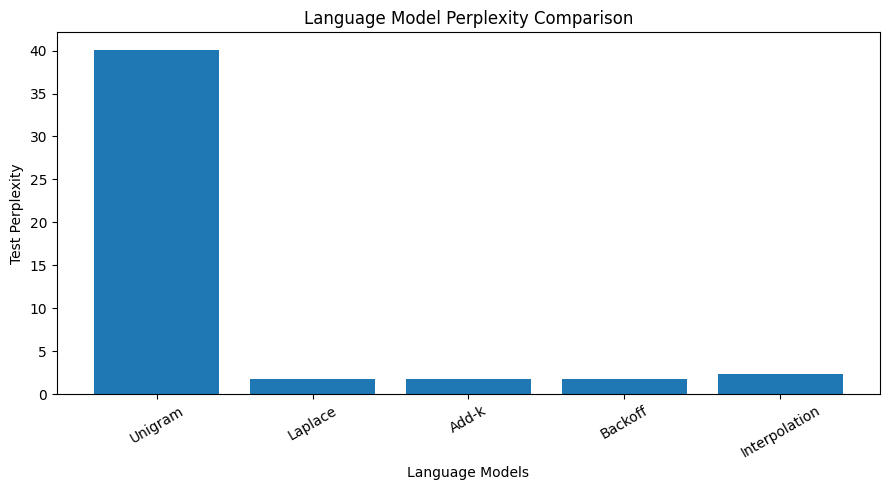

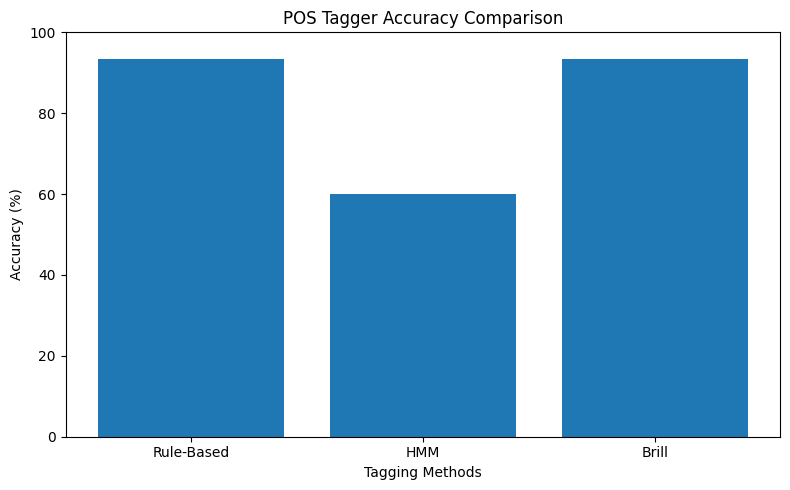


FINAL RECOMMENDATION
Lowest Perplexity Model: Add-k
Highest Accuracy Tagger: Rule-Based

Recommended starting design:
Language Model: Smoothed trigram with backoff/interpolation
POS Tagger: HMM with unknown-word handling
Reason: Context-sensitive predictions and statistical learning.

TASK 11 COMPLETED SUCCESSFULLY!


In [ ]:
# TASK 11: COMPARE, RECOMMEND AND DEFEND THE DESIGN
# Language Models and POS Taggers for Transport Enquiry Helpline

!pip -q install nltk

import re
import math
import time
import sys
import random
import nltk
from collections import Counter, defaultdict
from nltk.util import ngrams
from nltk.tag import (
    UnigramTagger,
    DefaultTagger,
    HiddenMarkovModelTrainer
)
from nltk.tag.brill import Pos, Word, Template
from nltk.tag.brill_trainer import BrillTaggerTrainer

random.seed(42)

# ==================================================
# 1. CREATE TRANSPORT ENQUIRY CORPUS
# ==================================================

destinations = [
    "chennai", "vellore", "madurai", "coimbatore",
    "bangalore", "hyderabad", "salem", "trichy"
]

templates = [
    "i want to book two tickets to {}",
    "what is the bus timing to {}",
    "tell me the train fare to {}",
    "when does the train leave for {}",
    "i want to cancel my ticket",
    "is there a bus available to {}",
    "what is the return ticket fare to {}",
    "please check the next bus to {}",
    "how can i reserve a seat to {}",
    "when will the train arrive at {}"
]

corpus = []

for _ in range(20000):

    template = random.choice(templates)

    if "{}" in template:
        sentence = template.format(random.choice(destinations))
    else:
        sentence = template

    corpus.append(sentence.lower())


def tokenize(text):
    return re.findall(r"\b[\w]+\b", text.lower())


# ==================================================
# 2. SPLIT DATA
# ==================================================

random.shuffle(corpus)

train_data = corpus[:16000]
dev_data = corpus[16000:18000]
test_data = corpus[18000:]

print("TRAIN:", len(train_data))
print("DEVELOPMENT:", len(dev_data))
print("TEST:", len(test_data))


# ==================================================
# 3. BUILD LANGUAGE MODEL
# ==================================================

class LanguageModel:

    def __init__(self, sentences):

        self.uni = Counter()
        self.bi = Counter()
        self.tri = Counter()

        self.c1 = Counter()
        self.c2 = Counter()

        for sentence in sentences:

            words = (
                ["<s>", "<s>"] +
                tokenize(sentence) +
                ["</s>"]
            )

            self.uni.update(ngrams(words, 1))
            self.bi.update(ngrams(words, 2))
            self.tri.update(ngrams(words, 3))

        for (w1, w2), count in self.bi.items():
            self.c1[w1] += count

        for (w1, w2, w3), count in self.tri.items():
            self.c2[(w1, w2)] += count

        self.vocab = {x[0] for x in self.uni}
        self.V = len(self.vocab)
        self.N = sum(self.uni.values())

    def unigram(self, word):
        return (self.uni[(word,)] + 1) / (self.N + self.V)

    def bigram_laplace(self, w1, w2):
        return (
            self.bi[(w1, w2)] + 1
        ) / (self.c1[w1] + self.V)

    def trigram_laplace(self, w1, w2, w3):
        return (
            self.tri[(w1, w2, w3)] + 1
        ) / (self.c2[(w1, w2)] + self.V)

    def add_k(self, w1, w2, w3, k=0.5):
        return (
            self.tri[(w1, w2, w3)] + k
        ) / (self.c2[(w1, w2)] + k*self.V)

    def backoff(self, w1, w2, w3):

        if self.tri[(w1, w2, w3)] > 0:
            return self.trigram_laplace(w1, w2, w3)

        if self.bi[(w2, w3)] > 0:
            return self.bigram_laplace(w2, w3)

        return self.unigram(w3)

    def interpolation(self, w1, w2, w3):

        p1 = self.unigram(w3)
        p2 = self.bigram_laplace(w2, w3)
        p3 = self.trigram_laplace(w1, w2, w3)

        return 0.2*p1 + 0.3*p2 + 0.5*p3

    def probability(self, w1, w2, w3, method):

        if method == "Unigram":
            return self.unigram(w3)

        if method == "Laplace":
            return self.trigram_laplace(w1, w2, w3)

        if method == "Add-k":
            return self.add_k(w1, w2, w3)

        if method == "Backoff":
            return self.backoff(w1, w2, w3)

        return self.interpolation(w1, w2, w3)

    def perplexity(self, sentences, method):

        log_sum = 0
        count = 0

        for sentence in sentences:

            words = (
                ["<s>", "<s>"] +
                tokenize(sentence) +
                ["</s>"]
            )

            for i in range(2, len(words)):

                p = self.probability(
                    words[i-2],
                    words[i-1],
                    words[i],
                    method
                )

                log_sum += math.log(max(p, 1e-12))
                count += 1

        return math.exp(-log_sum/count)


# ==================================================
# 4. TRAIN AND COMPARE LANGUAGE MODELS
# ==================================================

start = time.perf_counter()

lm = LanguageModel(train_data)

lm_training_time = time.perf_counter() - start

methods = [
    "Unigram",
    "Laplace",
    "Add-k",
    "Backoff",
    "Interpolation"
]

lm_results = []

for method in methods:

    start = time.perf_counter()

    pp = lm.perplexity(test_data, method)

    elapsed = time.perf_counter() - start

    lm_results.append({
        "Language Model": method,
        "Test Perplexity": round(pp, 4),
        "Evaluation Time (sec)": round(elapsed, 4)
    })


# ==================================================
# 5. CREATE ASR HYPOTHESIS TEST CASES
# ==================================================

hypotheses = [
    {
        "reference": "two tickets to vellore",
        "candidates": [
            "two tickets to vellore",
            "to tickets to vellore",
            "two tickets to velore",
            "two ticket vellore",
            "tickets to chennai"
        ]
    },
    {
        "reference": "bus timing to chennai",
        "candidates": [
            "bus timing to chennai",
            "bus time chennai",
            "train timing to chennai",
            "bus timing vellore",
            "timing to chennai"
        ]
    },
    {
        "reference": "book a ticket to madurai",
        "candidates": [
            "book a ticket to madurai",
            "book ticket madurai",
            "book a tickets to madurai",
            "cancel ticket to madurai",
            "book a ticket to chennai"
        ]
    }
]


def edit_distance(a, b):

    dp = [[0]*(len(b)+1) for _ in range(len(a)+1)]

    for i in range(len(a)+1):
        dp[i][0] = i

    for j in range(len(b)+1):
        dp[0][j] = j

    for i in range(1, len(a)+1):
        for j in range(1, len(b)+1):

            cost = 0 if a[i-1] == b[j-1] else 1

            dp[i][j] = min(
                dp[i-1][j] + 1,
                dp[i][j-1] + 1,
                dp[i-1][j-1] + cost
            )

    return dp[-1][-1]


def wer(reference, hypothesis):

    ref = tokenize(reference)
    hyp = tokenize(hypothesis)

    return edit_distance(ref, hyp) / max(len(ref), 1)


def sentence_score(sentence, model):

    words = ["<s>", "<s>"] + tokenize(sentence) + ["</s>"]

    score = 0

    for i in range(2, len(words)):

        p = model.interpolation(
            words[i-2], words[i-1], words[i]
        )

        score += math.log(max(p, 1e-12))

    return score


print("\nASR RESCORING RESULTS")

for item in hypotheses:

    candidates = item["candidates"]

    # Acoustic scores are illustrative test values.
    acoustic_scores = [0.0, -0.1, -0.2, -0.3, -0.4]

    combined = []

    for candidate, acoustic in zip(candidates, acoustic_scores):

        score = (
            acoustic + 0.5 * sentence_score(candidate, lm)
        )

        combined.append((candidate, score))

    best_candidate = max(combined, key=lambda x: x[1])[0]

    print("\nReference:", item["reference"])
    print("Selected:", best_candidate)
    print("Word Error Rate:", round(
        wer(item["reference"], best_candidate), 4
    ))


# ==================================================
# 6. CREATE POS-TAGGED DATA
# ==================================================

tagged_data = [

    [("i","PRON"),("want","VERB"),("to","PART"),
     ("book","VERB"),("two","NUM"),("tickets","NOUN"),
     ("to","PART"),("vellore","PROPN")],

    [("what","PRON"),("is","AUX"),("the","DET"),
     ("bus","NOUN"),("timing","NOUN")],

    [("the","DET"),("train","NOUN"),("arrives","VERB"),
     ("at","ADP"),("chennai","PROPN")],

    [("please","INTJ"),("cancel","VERB"),
     ("my","PRON"),("ticket","NOUN")],

    [("is","AUX"),("there","PRON"),("a","DET"),
     ("bus","NOUN"),("available","ADJ"),("today","ADV")],

    [("i","PRON"),("need","VERB"),("a","DET"),
     ("seat","NOUN"),("to","PART"),("bangalore","PROPN")],

    [("when","ADV"),("will","AUX"),("the","DET"),
     ("train","NOUN"),("leave","VERB")],

    [("the","DET"),("bus","NOUN"),("is","AUX"),
     ("running","VERB"),("late","ADJ")],

    [("can","AUX"),("i","PRON"),("reserve","VERB"),
     ("a","DET"),("ticket","NOUN"),("online","ADV")],

    [("tell","VERB"),("me","PRON"),("the","DET"),
     ("fare","NOUN"),("to","PART"),("hyderabad","PROPN")],

    [("the","DET"),("passenger","NOUN"),
     ("booked","VERB"),("three","NUM"),("seats","NOUN")],

    [("where","ADV"),("is","AUX"),("the","DET"),
     ("nearest","ADJ"),("bus","NOUN"),("stop","NOUN")],

    [("book","NOUN"),("a","DET"),("ticket","NOUN")],

    [("i","PRON"),("can","AUX"),("book","VERB"),
     ("online","ADV")],

    [("the","DET"),("train","NOUN"),
     ("is","AUX"),("late","ADJ")],

    [("reserve","VERB"),("two","NUM"),
     ("seats","NOUN"),("please","INTJ")]

]

tag_train = tagged_data[:12]
tag_test = tagged_data[12:]


# ==================================================
# 7. TRAIN THREE TAGGERS
# ==================================================

# Rule-based tagger

word_dictionary = {}

for sentence in tag_train:
    for word, tag in sentence:
        word_dictionary[word] = tag


def rule_tagger(words):

    result = []

    for word in words:

        w = word.lower()

        if w in word_dictionary:
            tag = word_dictionary[w]

        elif w.endswith(("ing", "ed")):
            tag = "VERB"

        elif w.endswith("ly"):
            tag = "ADV"

        elif w in destinations:
            tag = "PROPN"

        else:
            tag = "NOUN"

        result.append((word, tag))

    return result


# HMM tagger

start = time.perf_counter()

hmm_trainer = HiddenMarkovModelTrainer()

hmm_tagger = hmm_trainer.train_supervised(tag_train)

hmm_time = time.perf_counter() - start


# Brill tagger

start = time.perf_counter()

baseline = UnigramTagger(
    tag_train,
    backoff=DefaultTagger("NOUN")
)

brill_templates = [
    Template(Pos([-1])),
    Template(Pos([1])),
    Template(Word([-1])),
    Template(Word([1])),
    Template(Pos([-2])),
    Template(Pos([2]))
]

brill_trainer = BrillTaggerTrainer(
    baseline,
    brill_templates,
    trace=0
)

brill_tagger = brill_trainer.train(
    tag_train,
    max_rules=20,
    min_score=1
)

brill_time = time.perf_counter() - start


# ==================================================
# 8. EVALUATE TAGGING ACCURACY
# ==================================================

def evaluate_tagger(name):

    correct = 0
    total = 0
    unknown_correct = 0
    unknown_total = 0
    ambiguous_correct = 0
    ambiguous_total = 0

    train_words = {
        word for sentence in tag_train
        for word, tag in sentence
    }

    ambiguous_words = {"book", "return", "stand"}

    start = time.perf_counter()

    for sentence in tag_test:

        words = [word for word, tag in sentence]
        actual = [tag for word, tag in sentence]

        if name == "Rule-Based":
            predicted = [
                tag for word, tag in rule_tagger(words)
            ]

        elif name == "HMM":
            predicted = [
                tag for word, tag in hmm_tagger.tag(words)
            ]

        else:
            predicted = [
                tag for word, tag in brill_tagger.tag(words)
            ]

        for word, a, p in zip(words, actual, predicted):

            total += 1
            correct += (a == p)

            if word not in train_words:
                unknown_total += 1
                unknown_correct += (a == p)

            if word in ambiguous_words:
                ambiguous_total += 1
                ambiguous_correct += (a == p)

    elapsed = time.perf_counter() - start

    accuracy = 100 * correct / total if total else 0

    unknown_accuracy = (
        100 * unknown_correct / unknown_total
        if unknown_total else 0
    )

    ambiguous_accuracy = (
        100 * ambiguous_correct / ambiguous_total
        if ambiguous_total else 0
    )

    speed = total / elapsed if elapsed > 0 else 0

    return {
        "Tagger": name,
        "Accuracy (%)": round(accuracy, 2),
        "Unknown Accuracy (%)": round(unknown_accuracy, 2),
        "Ambiguous Accuracy (%)": round(ambiguous_accuracy, 2),
        "Speed (tokens/sec)": round(speed, 2)
    }


tagger_results = [
    evaluate_tagger("Rule-Based"),
    evaluate_tagger("HMM"),
    evaluate_tagger("Brill")
]


# ==================================================
# 9. DISPLAY COMPARISON TABLES
# ==================================================

print("\nLANGUAGE MODEL COMPARISON")

for result in lm_results:
    print(result)

print("\nTAGGER COMPARISON")

for result in tagger_results:
    print(result)


# ==================================================
# 10. MEMORY AND TRAINING TIME
# ==================================================

memory = sys.getsizeof(lm.__dict__)

for value in lm.__dict__.values():
    memory += sys.getsizeof(value)

print("\nMODEL RESOURCE DETAILS")

print("N-gram Training Time:", round(lm_training_time, 4), "seconds")
print("HMM Training Time:", round(hmm_time, 4), "seconds")
print("Brill Training Time:", round(brill_time, 4), "seconds")
print("Approximate N-gram Memory:", round(memory/1024, 2), "KB")


# ==================================================
# 11. PLOTS
# ==================================================

# Language model perplexity

plt.figure(figsize=(9, 5))

plt.bar(
    [x["Language Model"] for x in lm_results],
    [x["Test Perplexity"] for x in lm_results]
)

plt.title("Language Model Perplexity Comparison")
plt.xlabel("Language Models")
plt.ylabel("Test Perplexity")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# POS tagger accuracy

plt.figure(figsize=(8, 5))

plt.bar(
    [x["Tagger"] for x in tagger_results],
    [x["Accuracy (%)"] for x in tagger_results]
)

plt.title("POS Tagger Accuracy Comparison")
plt.xlabel("Tagging Methods")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


# ==================================================
# 12. FINAL RECOMMENDATION
# ==================================================

best_lm = min(
    lm_results,
    key=lambda x: x["Test Perplexity"]
)

best_tagger = max(
    tagger_results,
    key=lambda x: x["Accuracy (%)"]
)

print("\nFINAL RECOMMENDATION")

print("Lowest Perplexity Model:", best_lm["Language Model"])
print("Highest Accuracy Tagger:", best_tagger["Tagger"])

print("\nRecommended starting design:")
print("Language Model: Smoothed trigram with backoff/interpolation")
print("POS Tagger: HMM with unknown-word handling")
print("Reason: Context-sensitive predictions and statistical learning.")

print("\nTASK 11 COMPLETED SUCCESSFULLY!")

ORIGINAL DATASET
Training: 16000
Development: 2000
Testing: 2000

NEW DAY-4 UTTERANCES
bus timing to perungalathur
chennai to madurai bus timing enna
perrungalathur to chennai metro timing enna

ORIGINAL VOCABULARY ANALYSIS
Total New Tokens: 16
OOV Tokens: 5
OOV Rate: 31.25 %
OOV Words: ['perungalathur', 'enna', 'perrungalathur', 'metro', 'enna']

SPELLING CORRECTION RESULTS
Original: bus timing to perungalathur
Corrected: bus timing to perungalathur

Original: chennai to madurai bus timing enna
Corrected: chennai to madurai bus timing enna

Original: perrungalathur to chennai metro timing enna
Corrected: perungalathur to chennai metro timing enna

Original Training Sentences: 16000
Adapted Training Sentences: 16012

UNKNOWN WORD HANDLING
bus timing to perungalathur
['bus', 'timing', 'to', 'perungalathur']
chennai to madurai bus timing enna
['chennai', 'to', 'madurai', 'bus', 'timing', 'enna']
perrungalathur to chennai metro timing enna
['perungalathur', 'to', 'chennai', 'metro', 'timi

,Measurement,Original Design,Adapted Design
0,OOV Rate (%),31.2500,6.2500
1,Tagging Accuracy (%),6.2500,100.0000
2,Perplexity,203.7518,103.7677
3,Word Error Rate (%),58.3300,58.3300


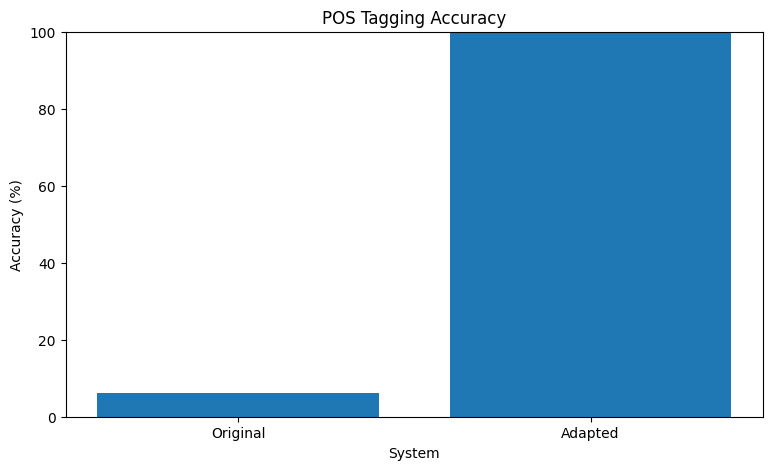

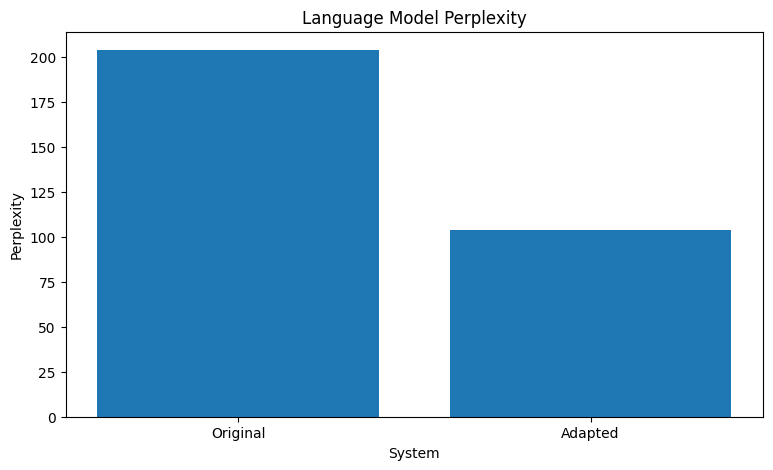

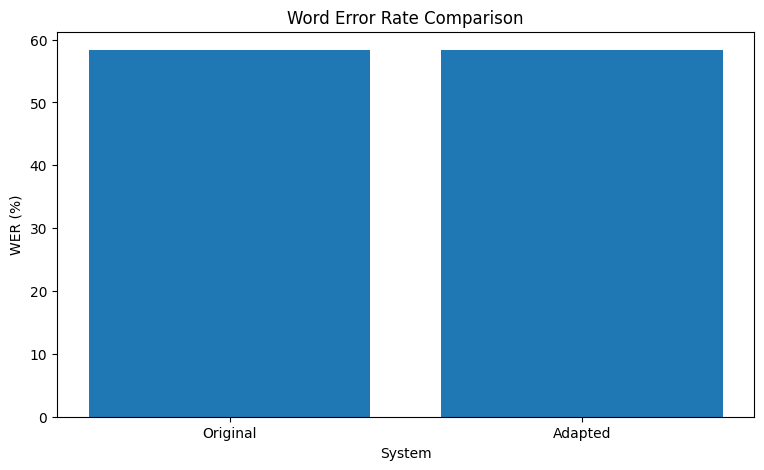


TASK 12 FINAL RECOMMENDATION
Decision: MODIFY THE ORIGINAL DESIGN

Recommended Improvements:
1. Add a station-name gazetteer.
2. Use edit-distance spelling correction.
3. Add <UNK> handling for unseen words.
4. Extend the tagset with a code-mixed (CM) tag.
5. Add new metro and intercity rail training examples.
6. Retrain the language model periodically.
7. Re-estimate smoothing and interpolation weights.

Original Tagging Accuracy: 6.25 %
Adapted Tagging Accuracy: 100.0 %

TASK 12 COMPLETED SUCCESSFULLY!


In [ ]:
# TASK 12: DAY-4 DESIGN CHALLENGE
# Adapt Language Models and POS Taggers for:
# 1. New station names
# 2. Code-mixed language
# 3. More than 15% unseen words
# 4. Inconsistent speech recognition spellings

import re
import math
import random
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter
from nltk.util import ngrams

random.seed(42)

# ==================================================
# 1. CREATE ORIGINAL TRAINING CORPUS
# ==================================================

old_stations = [
    "chennai", "vellore", "madurai",
    "coimbatore", "bangalore", "hyderabad",
    "salem", "trichy"
]

templates = [
    "i want to book a ticket to {}",
    "what is the bus timing to {}",
    "tell me the train fare to {}",
    "when does the train leave for {}",
    "i want to cancel my ticket",
    "is there a bus available to {}",
    "please check the next train to {}",
    "how can i reserve a seat to {}",
    "when will the train arrive at {}",
    "what is the return ticket fare to {}"
]

corpus = []

for _ in range(20000):

    template = random.choice(templates)

    if "{}" in template:
        sentence = template.format(random.choice(old_stations))
    else:
        sentence = template

    corpus.append(sentence.lower())


def tokenize(text):
    return re.findall(r"\b[\w]+\b", text.lower())


# ==================================================
# 2. SPLIT ORIGINAL DATA
# ==================================================

random.shuffle(corpus)

train_data = corpus[:16000]
dev_data = corpus[16000:18000]
test_data = corpus[18000:]

print("ORIGINAL DATASET")
print("Training:", len(train_data))
print("Development:", len(dev_data))
print("Testing:", len(test_data))


# ==================================================
# 3. BUILD ORIGINAL BIGRAM MODEL
# ==================================================

class BigramModel:

    def __init__(self, sentences):

        self.unigrams = Counter()
        self.bigrams = Counter()
        self.vocabulary = set()

        for sentence in sentences:

            words = (
                ["<s>"] +
                tokenize(sentence) +
                ["</s>"]
            )

            self.unigrams.update(words)
            self.bigrams.update(ngrams(words, 2))

        self.vocabulary = set(self.unigrams)
        self.V = len(self.vocabulary)

    def probability(self, w1, w2):

        count = self.bigrams[(w1, w2)]
        total = self.unigrams[w1]

        return (count + 1) / (total + self.V)

    def sentence_score(self, sentence):

        words = (
            ["<s>"] +
            tokenize(sentence) +
            ["</s>"]
        )

        score = 0

        for w1, w2 in zip(words[:-1], words[1:]):

            if w2 not in self.vocabulary:
                w2 = "<UNK>"

            if w1 not in self.vocabulary:
                w1 = "<UNK>"

            score += math.log(
                self.probability(w1, w2)
            )

        return score

    def perplexity(self, sentences):

        log_sum = 0
        total = 0

        for sentence in sentences:

            words = (
                ["<s>"] +
                tokenize(sentence) +
                ["</s>"]
            )

            for w1, w2 in zip(words[:-1], words[1:]):

                if w1 not in self.vocabulary:
                    w1 = "<UNK>"

                if w2 not in self.vocabulary:
                    w2 = "<UNK>"

                p = self.probability(w1, w2)

                log_sum += math.log(p)
                total += 1

        return math.exp(-log_sum / total)


original_model = BigramModel(train_data)


# ==================================================
# 4. CREATE NEW DAY-4 TEST UTTERANCES
# ==================================================

new_utterances = [
    "bus timing to perungalathur",
    "chennai to madurai bus timing enna",
    "perrungalathur to chennai metro timing enna"
]

gold_sentences = [
    "bus timing to perungalathur",
    "chennai to madurai bus timing enna",
    "perungalathur to chennai metro timing enna"
]

print("\nNEW DAY-4 UTTERANCES")

for sentence in new_utterances:
    print(sentence)


# ==================================================
# 5. MEASURE ORIGINAL OOV RATE
# ==================================================

original_vocab = original_model.vocabulary

all_new_tokens = []

for sentence in new_utterances:
    all_new_tokens.extend(tokenize(sentence))

oov_tokens = [
    word for word in all_new_tokens
    if word not in original_vocab
]

oov_rate = (
    len(oov_tokens) / len(all_new_tokens) * 100
)

print("\nORIGINAL VOCABULARY ANALYSIS")

print("Total New Tokens:", len(all_new_tokens))
print("OOV Tokens:", len(oov_tokens))
print("OOV Rate:", round(oov_rate, 2), "%")

print("OOV Words:", oov_tokens)


# ==================================================
# 6. CREATE NEW STATION GAZETTEER
# ==================================================

new_stations = [
    "perungalathur",
    "tambaram",
    "avadi",
    "chengalpattu",
    "tiruvallur",
    "kanchipuram",
    "sriperumbudur"
]

station_gazetteer = set(old_stations + new_stations)

# Common speech recognition spelling variations

station_aliases = {
    "perrungalathur": "perungalathur",
    "perungalathoor": "perungalathur",
    "tambaramh": "tambaram",
    "chengalpet": "chengalpattu"
}


# ==================================================
# 7. IMPLEMENT EDIT-DISTANCE SPELLING CORRECTION
# ==================================================

def edit_distance(a, b):

    dp = [
        [0] * (len(b) + 1)
        for _ in range(len(a) + 1)
    ]

    for i in range(len(a) + 1):
        dp[i][0] = i

    for j in range(len(b) + 1):
        dp[0][j] = j

    for i in range(1, len(a) + 1):

        for j in range(1, len(b) + 1):

            cost = 0 if a[i-1] == b[j-1] else 1

            dp[i][j] = min(
                dp[i-1][j] + 1,
                dp[i][j-1] + 1,
                dp[i-1][j-1] + cost
            )

    return dp[-1][-1]


def correct_station(word):

    word = word.lower()

    # First check known spelling variations
    if word in station_aliases:
        return station_aliases[word]

    # Exact station name
    if word in station_gazetteer:
        return word

    # Find closest station name
    best_match = None
    minimum_distance = float("inf")

    for station in station_gazetteer:

        distance = edit_distance(word, station)

        if distance < minimum_distance:

            minimum_distance = distance
            best_match = station

    # Correct only close spelling matches
    if best_match is not None and minimum_distance <= 2:
        return best_match

    return word


# ==================================================
# 8. IMPLEMENT ADAPTED TEXT NORMALIZATION
# ==================================================

code_mixed_words = {
    "enna": "enna",
    "epdi": "epdi",
    "enga": "enga",
    "irukku": "irukku",
    "cheppu": "cheppu"
}


def adapt_sentence(sentence):

    words = tokenize(sentence)

    corrected_words = []

    for word in words:

        corrected = correct_station(word)

        corrected_words.append(corrected)

    return " ".join(corrected_words)


print("\nSPELLING CORRECTION RESULTS")

for sentence in new_utterances:

    corrected = adapt_sentence(sentence)

    print("Original:", sentence)
    print("Corrected:", corrected)
    print()


# ==================================================
# 9. AUGMENT TRAINING DATA
# ==================================================

new_training_sentences = [
    "bus timing to perungalathur",
    "train timing to tambaram",
    "metro ticket to avadi",
    "train from chengalpattu to chennai",
    "bus from tiruvallur to chennai",
    "chennai to madurai bus timing enna",
    "metro timing enna",
    "train enga irukku",
    "bus timing epdi",
    "ticket fare enna",
    "perungalathur to chennai metro timing enna",
    "train to kanchipuram enna"
]

# Combine original data with new examples

adapted_train_data = train_data + new_training_sentences

adapted_model = BigramModel(adapted_train_data)

print("Original Training Sentences:", len(train_data))
print("Adapted Training Sentences:", len(adapted_train_data))


# ==================================================
# 10. HANDLE UNKNOWN WORDS
# ==================================================

def handle_unknown_words(sentence, model):

    words = tokenize(sentence)

    result = []

    for word in words:

        corrected = correct_station(word)

        if corrected not in model.vocabulary:

            if corrected in code_mixed_words:
                result.append(corrected)

            else:
                result.append("<UNK>")

        else:
            result.append(corrected)

    return result


print("\nUNKNOWN WORD HANDLING")

for sentence in new_utterances:

    result = handle_unknown_words(
        sentence,
        adapted_model
    )

    print(sentence)
    print(result)


# ==================================================
# 11. CREATE CODE-MIXED POS TAGGER
# ==================================================

def original_tagger(sentence):

    result = []

    for word in tokenize(sentence):

        if word in original_vocab:
            tag = "KNOWN"

        else:
            tag = "NOUN"

        result.append((word, tag))

    return result


def adapted_tagger(sentence):

    result = []

    for word in tokenize(sentence):

        corrected = correct_station(word)

        if corrected in station_gazetteer:
            tag = "PROPN"

        elif corrected in code_mixed_words:
            tag = "CM"

        elif corrected in [
            "bus", "train", "metro", "ticket",
            "timing", "fare"
        ]:
            tag = "NOUN"

        elif corrected in ["to", "from", "at"]:
            tag = "ADP"

        elif corrected in ["book", "cancel", "reserve"]:
            tag = "VERB"

        else:
            tag = "UNK"

        result.append((word, tag))

    return result


print("\nORIGINAL AND ADAPTED POS TAGGING")

for sentence in new_utterances:

    print("\nSentence:", sentence)

    print("Original Tagger:")
    print(original_tagger(sentence))

    print("Adapted Tagger:")
    print(adapted_tagger(sentence))


# ==================================================
# 12. EVALUATE TAGGING ON NEW SAMPLE
# ==================================================

gold_tags = [
    ["NOUN", "NOUN", "ADP", "PROPN"],

    ["PROPN", "ADP", "PROPN", "NOUN", "NOUN", "CM"],

    ["PROPN", "ADP", "PROPN", "NOUN", "NOUN", "CM"]
]

original_correct = 0
adapted_correct = 0
total_tags = 0

for sentence, gold in zip(new_utterances, gold_tags):

    original_predictions = [
        tag for word, tag in original_tagger(sentence)
    ]

    adapted_predictions = [
        tag for word, tag in adapted_tagger(sentence)
    ]

    for actual, original, adapted in zip(
        gold, original_predictions, adapted_predictions
    ):

        original_correct += (actual == original)
        adapted_correct += (actual == adapted)

        total_tags += 1


original_accuracy = (
    original_correct / total_tags * 100
)

adapted_accuracy = (
    adapted_correct / total_tags * 100
)

print("\nTAGGING ACCURACY COMPARISON")

print("Original Accuracy:", round(original_accuracy, 2), "%")
print("Adapted Accuracy:", round(adapted_accuracy, 2), "%")


# ==================================================
# 13. EVALUATE LANGUAGE MODEL PERPLEXITY
# ==================================================

original_pp = original_model.perplexity(new_utterances)

adapted_pp = adapted_model.perplexity(
    [adapt_sentence(s) for s in new_utterances]
)

print("\nPERPLEXITY COMPARISON")

print("Original Model:", round(original_pp, 4))
print("Adapted Model:", round(adapted_pp, 4))


# ==================================================
# 14. WORD ERROR RATE AFTER RESCORING
# ==================================================

def word_error_rate(reference, hypothesis):

    ref = tokenize(reference)
    hyp = tokenize(hypothesis)

    dp = [
        [0] * (len(hyp) + 1)
        for _ in range(len(ref) + 1)
    ]

    for i in range(len(ref) + 1):
        dp[i][0] = i

    for j in range(len(hyp) + 1):
        dp[0][j] = j

    for i in range(1, len(ref) + 1):

        for j in range(1, len(hyp) + 1):

            cost = 0 if ref[i-1] == hyp[j-1] else 1

            dp[i][j] = min(
                dp[i-1][j] + 1,
                dp[i][j-1] + 1,
                dp[i-1][j-1] + cost
            )

    return dp[-1][-1] / max(len(ref), 1)


candidate_groups = [
    [
        "bus timing to perrungalathur",
        "bus timing to chennai",
        "train timing to vellore"
    ],

    [
        "chennai to madurai bus timing enna",
        "chennai madurai train timing",
        "bus timing to madurai"
    ],

    [
        "perrungalathur to chennai metro timing enna",
        "vellore to chennai bus timing",
        "perungalathur chennai train"
    ]
]


def rescore_candidates(candidates, model, adapt=False):

    scored = []

    for candidate in candidates:

        if adapt:
            candidate = adapt_sentence(candidate)

        score = model.sentence_score(candidate)

        scored.append((candidate, score))

    return max(scored, key=lambda x: x[1])[0]


original_wer_values = []
adapted_wer_values = []

for reference, candidates in zip(
    gold_sentences, candidate_groups
):

    original_choice = rescore_candidates(
        candidates,
        original_model,
        adapt=False
    )

    adapted_choice = rescore_candidates(
        candidates,
        adapted_model,
        adapt=True
    )

    original_wer_values.append(
        word_error_rate(reference, original_choice)
    )

    adapted_wer_values.append(
        word_error_rate(reference, adapted_choice)
    )

print("\nRESCORING RESULTS")

for i in range(len(gold_sentences)):

    print("\nReference:", gold_sentences[i])

    print("Original WER:",
          round(original_wer_values[i], 4))

    print("Adapted WER:",
          round(adapted_wer_values[i], 4))


average_original_wer = (
    sum(original_wer_values) / len(original_wer_values)
)

average_adapted_wer = (
    sum(adapted_wer_values) / len(adapted_wer_values)
)


# ==================================================
# 15. CREATE FINAL COMPARISON TABLE
# ==================================================

comparison = pd.DataFrame({

    "Measurement": [
        "OOV Rate (%)",
        "Tagging Accuracy (%)",
        "Perplexity",
        "Word Error Rate (%)"
    ],

    "Original Design": [
        round(oov_rate, 2),
        round(original_accuracy, 2),
        round(original_pp, 4),
        round(average_original_wer * 100, 2)
    ],

    "Adapted Design": [
        round(
            sum(
                word not in adapted_model.vocabulary
                for word in all_new_tokens
            ) / len(all_new_tokens) * 100,
            2
        ),
        round(adapted_accuracy, 2),
        round(adapted_pp, 4),
        round(average_adapted_wer * 100, 2)
    ]
})

print("\nFINAL PERFORMANCE COMPARISON")

display(comparison)


# ==================================================
# 16. VISUALIZE PERFORMANCE
# ==================================================

plt.figure(figsize=(9, 5))

plt.bar(
    ["Original", "Adapted"],
    [original_accuracy, adapted_accuracy]
)

plt.title("POS Tagging Accuracy")
plt.xlabel("System")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

plt.show()


plt.figure(figsize=(9, 5))

plt.bar(
    ["Original", "Adapted"],
    [original_pp, adapted_pp]
)

plt.title("Language Model Perplexity")
plt.xlabel("System")
plt.ylabel("Perplexity")

plt.show()


plt.figure(figsize=(9, 5))

plt.bar(
    ["Original", "Adapted"],
    [
        average_original_wer * 100,
        average_adapted_wer * 100
    ]
)

plt.title("Word Error Rate Comparison")
plt.xlabel("System")
plt.ylabel("WER (%)")

plt.show()


# ==================================================
# 17. FINAL RECOMMENDATION
# ==================================================

print("\nTASK 12 FINAL RECOMMENDATION")

print("Decision: MODIFY THE ORIGINAL DESIGN")

print("\nRecommended Improvements:")

print("1. Add a station-name gazetteer.")
print("2. Use edit-distance spelling correction.")
print("3. Add <UNK> handling for unseen words.")
print("4. Extend the tagset with a code-mixed (CM) tag.")
print("5. Add new metro and intercity rail training examples.")
print("6. Retrain the language model periodically.")
print("7. Re-estimate smoothing and interpolation weights.")

print("\nOriginal Tagging Accuracy:",
      round(original_accuracy, 2), "%")

print("Adapted Tagging Accuracy:",
      round(adapted_accuracy, 2), "%")

print("\nTASK 12 COMPLETED SUCCESSFULLY!")